<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/21_Bases_Datos_Vectoriales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Bases de datos vectoriales: índices, motores, frameworks y proveedores</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">1. Introducción</span>](#introduccion)
- [<span style="color: #005C99;">2. Configuración y proveedores</span>](#configuracion-y-proveedores)
- [<span style="color: #005C99;">3. Los datos y la búsqueda exacta</span>](#datos-y-busqueda-exacta)
- [<span style="color: #005C99;">4. Índices de vecinos aproximados</span>](#indices-aproximados)
- [<span style="color: #005C99;">5. Cuantización y reducción de dimensiones</span>](#cuantizacion)
- [<span style="color: #005C99;">6. Bases de datos vectoriales en la práctica</span>](#bases-de-datos)
- [<span style="color: #005C99;">7. Filtros por metadatos</span>](#filtros)
- [<span style="color: #005C99;">8. Búsqueda híbrida dentro de la base de datos</span>](#busqueda-hibrida)
- [<span style="color: #005C99;">9. Frameworks: LangChain y LlamaIndex</span>](#frameworks)
- [<span style="color: #005C99;">10. Proveedores gestionados y cómo elegir</span>](#proveedores)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn python-dotenv openai google-genai ollama faiss-cpu hnswlib chromadb qdrant-client lancedb pymilvus milvus-lite pyarrow langchain-core langchain-chroma langchain-qdrant langchain-community llama-index-core llama-index-vector-stores-chroma llama-index-vector-stores-qdrant

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import json
import math
import time
import unicodedata
import warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore")

In [3]:
import shutil
import tempfile
from pathlib import Path

DIRECTORIO = Path(tempfile.mkdtemp(prefix="vectores_"))     # aquí guardan sus archivos las bases de datos de este cuaderno

<a id="introduccion"></a>
<h2 style="color: #007ACC;">1. Introducción</h2>

En el cuaderno 20 construimos un RAG con una base de conocimiento de unos cientos de fragmentos, y la «base de datos» era una matriz de NumPy: buscar era multiplicarla por el vector de la consulta (sección 9.3 de ese cuaderno). Eso es exacto, simple y suficiente hasta cientos de miles de vectores. Pero una aplicación real pide más, y ahí aparecen las **bases de datos vectoriales** (*vector databases*), cuyo trabajo es guardar vectores junto con sus datos y **encontrar los más cercanos a uno dado** de forma eficiente. Lo que añaden a la matriz de NumPy:

| Necesidad | Qué aporta una base de datos vectorial |
|---|---|
| **Velocidad a escala** | Índices de **vecinos aproximados** (ANN) que miran una fracción pequeña de los vectores: de lineal a casi logarítmico |
| **Memoria** | **Cuantización** y almacenamiento en disco, para que millones de vectores quepan |
| **Persistencia** | Los datos sobreviven al proceso, con copias de seguridad y recuperación |
| **Datos junto a los vectores** | Texto, **metadatos** y **filtros** («solo documentos vigentes del área de finanzas») |
| **Cambios** | Insertar, actualizar y borrar sin reconstruir todo |
| **Operación** | Concurrencia, replicación, particionado, control de acceso, monitoreo |

El mercado se llenó de opciones (bibliotecas, bases de datos especializadas, extensiones de bases de datos que ya conoces y servicios gestionados) y de **frameworks** que prometen una interfaz común. Este cuaderno tiene dos propósitos: entender **qué hay dentro** (los índices y sus compromisos) y **probar** varias herramientas con los mismos datos y las mismas preguntas, para poder elegir con criterio.

**Plan.**
- **Secciones 3 a 5, el motor.** Los datos, la búsqueda exacta como referencia, los índices aproximados (IVF, HNSW) y la compresión (cuantización, vectores más cortos), todo medido en velocidad, memoria y **recall**.
- **Sección 6, las herramientas.** El mismo conjunto de operaciones (insertar, buscar, filtrar, borrar, persistir) en **FAISS, Chroma, Qdrant, LanceDB y Milvus**.
- **Secciones 7 y 8, lo que importa en un RAG.** Filtros por metadatos y búsqueda híbrida dentro de la base de datos.
- **Sección 9, los frameworks.** **LangChain** y **LlamaIndex**: la misma aplicación cambiando de base de datos en una línea (y qué se filtra de la abstracción).
- **Sección 10, los proveedores.** Pinecone, pgvector, Weaviate, Elasticsearch, los servicios de las nubes y una guía para elegir.

> **Qué se ejecuta y qué no.** Las herramientas de las secciones 3 a 9 corren **en tu equipo**, sin servidores ni cuentas (en modo local o embebido). Los servicios gestionados y los que necesitan un servidor (Pinecone, pgvector, Weaviate, Elasticsearch...) se explican con fragmentos de código que **no se ejecutan aquí**. Las bases de datos cambian con rapidez: los nombres de los parámetros y las capacidades que ves en este cuaderno corresponden a las versiones instaladas; contrasta siempre con la documentación vigente.

<a id="configuracion-y-proveedores"></a>
<h2 style="color: #007ACC;">2. Configuración y proveedores</h2>

Igual que en el cuaderno 20, usamos las claves del archivo `.env` (`OPENAI_API_KEY` y `GOOGLE_API_KEY`; en Colab, los *Secretos*) y **un solo proveedor** para los embeddings y el LLM: el primero disponible entre OpenAI, Google y Ollama. Los embeddings son lo único que cuesta dinero aquí (embeber unos 8.000 textos cortos cuesta centavos); las bases de datos que probamos son gratuitas y locales.

In [4]:
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))  # busca el .env en la carpeta actual y en las superiores


def obtener_clave(nombre):
    """Lee la clave del entorno (.env) o, en Google Colab, de los Secretos. Nunca se imprime."""
    clave = os.environ.get(nombre)
    if not clave:
        try:
            from google.colab import userdata
            clave = userdata.get(nombre)
        except Exception:
            clave = None
    return clave


# Los nombres de los modelos cambian con frecuencia: si alguno falla, consulta la lista del proveedor y cámbialo aquí.
MODELO_OPENAI, EMB_OPENAI = "gpt-4.1-mini", "text-embedding-3-small"
MODELO_GOOGLE, EMB_GOOGLE = "gemini-3.5-flash-lite", "gemini-embedding-001"
MODELO_OLLAMA, EMB_OLLAMA = "llama3.2:3b", "nomic-embed-text"   # para Ollama: `ollama pull llama3.2:3b` y `ollama pull nomic-embed-text`

CLAVE_OPENAI = obtener_clave("OPENAI_API_KEY")
CLAVE_GOOGLE = obtener_clave("GOOGLE_API_KEY")


def ollama_tiene(modelo):
    """¿Está el servidor de Ollama activo y el modelo descargado?"""
    try:
        import ollama
        return any(m.model.split(":")[0] == modelo.split(":")[0] and (":" not in modelo or m.model == modelo)
                   for m in ollama.Client().list().models)
    except Exception:
        return False


estado = {
    "OpenAI": (MODELO_OPENAI, EMB_OPENAI, "lista" if CLAVE_OPENAI else "falta OPENAI_API_KEY"),
    "Google": (MODELO_GOOGLE, EMB_GOOGLE, "lista" if CLAVE_GOOGLE else "falta GOOGLE_API_KEY"),
    "Ollama": (MODELO_OLLAMA, EMB_OLLAMA, "lista" if ollama_tiene(MODELO_OLLAMA) and ollama_tiene(EMB_OLLAMA)
               else "falta el servidor o alguno de los dos modelos"),
}
display(pd.DataFrame(estado, index=["modelo de chat", "modelo de embeddings", "estado"]).T)
DISPONIBLES = [proveedor for proveedor, (_, _, e) in estado.items() if e == "lista"]
assert DISPONIBLES, "Configura al menos un proveedor (ver arriba) para ejecutar el resto del cuaderno."
PRINCIPAL = DISPONIBLES[0]   # el proveedor con el que corre todo el cuaderno (chat y embeddings)
print("Proveedor que usaremos:", PRINCIPAL)

,modelo de chat,modelo de embeddings,estado
OpenAI,gpt-4.1-mini,text-embedding-3-small,lista
Google,gemini-3.5-flash-lite,gemini-embedding-001,lista
Ollama,llama3.2:3b,nomic-embed-text,falta el servidor o alguno de los dos modelos


Proveedor que usaremos: OpenAI


In [5]:
import threading
import ollama
from openai import OpenAI
from google import genai
from google.genai import types

CLIENTE = {"OpenAI": lambda: OpenAI(api_key=CLAVE_OPENAI),
           "Google": lambda: genai.Client(api_key=CLAVE_GOOGLE),
           "Ollama": lambda: ollama.Client()}[PRINCIPAL]()
MODELO_CHAT, MODELO_EMB = {p: (m, e) for p, (m, e, _) in estado.items()}[PRINCIPAL]

USO = Counter()           # bitácora global: llamadas al LLM, tokens y textos enviados a embeddings
_candado = threading.Lock()


def es_transitorio(error):
    """Errores que vale la pena reintentar: límite de tasa, fallas del servidor y cortes de red."""
    codigo = getattr(error, "status_code", None) or getattr(error, "code", None)
    return codigo in (408, 429, 500, 502, 503, 504) or any(p in type(error).__name__ for p in ("Connection", "Timeout"))


def reintentar(funcion):
    for intento in range(7):
        try:
            return funcion()
        except Exception as error:
            if intento == 6 or not es_transitorio(error):
                raise
            time.sleep(2 ** intento)


def generar(prompt, sistema=None, max_tokens=700, como_json=False):
    """Una llamada al modelo de chat del proveedor principal. Con `como_json=True` devuelve un diccionario."""
    def llamar():
        if PRINCIPAL == "OpenAI":
            mensajes = ([{"role": "system", "content": sistema}] if sistema else []) + [{"role": "user", "content": prompt}]
            extra = {"response_format": {"type": "json_object"}} if como_json else {}
            r = CLIENTE.chat.completions.create(model=MODELO_CHAT, messages=mensajes, temperature=0,
                                                max_completion_tokens=max_tokens, **extra)
            return r.choices[0].message.content or "", r.usage.prompt_tokens, r.usage.completion_tokens
        if PRINCIPAL == "Google":
            config = dict(system_instruction=sistema, temperature=0, max_output_tokens=max_tokens + 1500)  # + margen para el "pensamiento"
            if como_json:
                config["response_mime_type"] = "application/json"
            r = CLIENTE.models.generate_content(model=MODELO_CHAT, contents=prompt, config=types.GenerateContentConfig(**config))
            u = r.usage_metadata
            return r.text or "", u.prompt_token_count or 0, (u.candidates_token_count or 0) + (u.thoughts_token_count or 0)
        mensajes = ([{"role": "system", "content": sistema}] if sistema else []) + [{"role": "user", "content": prompt}]
        r = CLIENTE.chat(model=MODELO_CHAT, messages=mensajes, format="json" if como_json else None,
                         options={"temperature": 0, "num_predict": max_tokens})
        return r.message.content or "", r.prompt_eval_count or 0, r.eval_count or 0

    texto, t_in, t_out = reintentar(llamar)
    with _candado:
        USO["llamadas"] += 1
        USO["tokens_entrada"] += t_in
        USO["tokens_salida"] += t_out
    if not como_json:
        return texto.strip()
    try:
        return json.loads(re.sub(r"^```(?:json)?|```$", "", texto.strip(), flags=re.M).strip())
    except json.JSONDecodeError:
        return {}


def normalizar(texto):
    """Minúsculas y sin tildes, para comparar textos."""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode().lower()).strip()


_cache_emb = {}


def embeber(textos, lote=96):
    """Embeddings normalizados (cada fila tiene norma 1: el producto punto es la similitud coseno). Con caché en memoria."""
    pendientes = [t for t in dict.fromkeys(textos) if t not in _cache_emb]
    for i in range(0, len(pendientes), lote):
        parte = pendientes[i:i + lote]
        if PRINCIPAL == "OpenAI":
            vectores = [d.embedding for d in reintentar(lambda: CLIENTE.embeddings.create(model=MODELO_EMB, input=parte)).data]
        elif PRINCIPAL == "Google":
            vectores = [e.values for e in reintentar(lambda: CLIENTE.models.embed_content(model=MODELO_EMB, contents=parte)).embeddings]
        else:
            vectores = reintentar(lambda: CLIENTE.embed(model=MODELO_EMB, input=parte)).embeddings
        for t, v in zip(parte, vectores):
            v = np.asarray(v, dtype=np.float32)
            _cache_emb[t] = v / np.linalg.norm(v)
        USO["textos_embebidos"] += len(parte)
    return np.vstack([_cache_emb[t] for t in textos])


def en_paralelo(funcion, elementos, hilos=6):
    """Aplica `funcion` a cada elemento con varios hilos (las llamadas a una API pasan casi todo el tiempo esperando)."""
    with ThreadPoolExecutor(hilos) as pool:
        return list(pool.map(funcion, elementos))


v = embeber(["Hola", "¿Cómo estás?"])
print(f"Proveedor: {PRINCIPAL} | chat: {MODELO_CHAT} | embeddings: {MODELO_EMB} ({v.shape[1]} dimensiones)")
print("Respuesta de prueba:", generar("Responde solo con la palabra: listo"))

Proveedor: OpenAI | chat: gpt-4.1-mini | embeddings: text-embedding-3-small (1536 dimensiones)


Respuesta de prueba: listo


<a id="datos-y-busqueda-exacta"></a>
<h2 style="color: #007ACC;">3. Los datos y la búsqueda exacta</h2>

Necesitamos vectores **reales** y suficientes para que las diferencias se noten. Usamos **20 Newsgroups**, un corpus clásico de mensajes de foros de discusión agrupados en 20 temas (cuadernos 4 y 7), con el que ya trabajaste en otros cuadernos. Tomamos 8.300 mensajes de entre 300 y 4.000 caracteres, nos quedamos con los primeros 800 caracteres de cada uno y los dividimos así:

- **8.000 documentos** que van a la base de datos, cada uno con sus **metadatos**: el grupo (`rec.autos`, `sci.space`...), el tema general (`rec`, `sci`, `comp`...) y el largo del mensaje original.
- **300 consultas** que no están en la base: el comienzo de otros mensajes (250 caracteres). Son nuestras «preguntas».

El conjunto es modesto a propósito: cabe en cualquier equipo y permite repetir todo en minutos. Para la parte de escala (sección 4.5) usaremos vectores sintéticos mucho más numerosos.

In [6]:
from sklearn.datasets import fetch_20newsgroups

bruto = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes"))
candidatos = []
for texto, y in zip(bruto.data, bruto.target):
    t = re.sub(r"\s+", " ", texto).strip()
    if 300 <= len(t) <= 4000:
        candidatos.append({"texto": t[:800], "grupo": bruto.target_names[y], "largo": len(t)})

N_CONSULTAS, N_DOCS = 300, 8000
elegidos = rng.permutation(len(candidatos))[:N_CONSULTAS + N_DOCS]
tabla = pd.DataFrame([candidatos[i] for i in elegidos]).reset_index(drop=True)
tabla["tema"] = tabla.grupo.str.split(".").str[0]
CONSULTAS = tabla.iloc[:N_CONSULTAS].reset_index(drop=True)
DOCS = tabla.iloc[N_CONSULTAS:].reset_index(drop=True)
print(f"{len(DOCS)} documentos y {len(CONSULTAS)} consultas | {DOCS.grupo.nunique()} grupos, {DOCS.tema.nunique()} temas")
display(DOCS.tema.value_counts().to_frame("documentos").T)
print("\nEjemplo:", DOCS.loc[0, "grupo"], "·", DOCS.loc[0, "texto"][:200], "...")

8000 documentos y 300 consultas | 20 grupos, 7 temas


tema,comp,sci,rec,talk,soc,misc,alt
documentos,2009,1771,1567,1429,503,371,350



Ejemplo: sci.space · Hey! My dad has an old hangar and Judy has some old rockets in her attic, let's put on a Lunar program! . . . Sounds good, but . . . Let's play a game - What would be a reasonable reward? What compani ...


Ahora los **embeddings**. Con 8.300 textos, la llamada por lotes y en paralelo importa: `embeber_muchos` reparte los lotes entre varios hilos y deja los resultados en la caché de `embeber`.

In [7]:
def embeber_muchos(textos, lote=96, hilos=3):
    """Embeddings de muchos textos: los lotes se piden en paralelo y luego se juntan en una sola matriz."""
    en_paralelo(embeber, [textos[i:i + lote] for i in range(0, len(textos), lote)], hilos)
    return embeber(textos)


t0 = time.perf_counter()
E = embeber_muchos(DOCS.texto.tolist())                    # (8000, dimensiones), normalizada
Q = embeber_muchos(CONSULTAS.texto.str.slice(0, 250).tolist())
print(f"Documentos: {E.shape} | consultas: {Q.shape} | {time.perf_counter() - t0:.0f} s | {E.nbytes / 1e6:.0f} MB en float32")

Documentos: (8000, 1536) | consultas: (300, 1536) | 55 s | 49 MB en float32


**La referencia: búsqueda exacta.** Para cada consulta, el producto punto con los 8.000 vectores y los 10 más altos. Es lo que hacíamos en el cuaderno 20, y es la **verdad de referencia** (*ground truth*) para medir todo lo demás: un índice aproximado se mide por cuántos de estos 10 vecinos exactos recupera (**recall@10**) y a qué costo.

Dos cosas conviene tener claras antes de seguir. Primero, **recall@10 mide fidelidad a la búsqueda exacta, no calidad de la respuesta**: un índice con recall 0,9 deja de encontrar uno de cada diez vecinos exactos, pero los que encuentra suelen ser casi igual de buenos. Segundo, la similitud: con vectores **normalizados** (como los que devuelve `embeber`), el coseno, el producto punto y la distancia euclídea **ordenan igual**, porque $\lVert a-b\rVert^2 = 2 - 2\,a\cdot b$. Lo comprobamos, y vemos qué pasa cuando los vectores no están normalizados:

In [8]:
def exacta(Q, E, k=10):
    """Los k vecinos exactos de cada consulta (posiciones en E), de mayor a menor similitud."""
    S = Q @ E.T
    cand = np.argpartition(-S, k, axis=1)[:, :k]
    orden = np.argsort(-np.take_along_axis(S, cand, 1), axis=1)
    return np.take_along_axis(cand, orden, 1)


def recall(pred, verdad):
    """Fracción de los vecinos exactos que el método recuperó, promediada sobre las consultas."""
    return float(np.mean([len(set(p) & set(v)) / len(v) for p, v in zip(pred, verdad)]))


GT = exacta(Q, E, 10)

q = Q[0]
por_producto = np.argsort(-(E @ q))[:10]
por_euclidea = np.argsort(((E - q) ** 2).sum(1))[:10]
print("Normalizados: ¿producto punto y distancia euclídea dan el mismo orden?", bool((por_producto == por_euclidea).all()))

E_desiguales = E * rng.uniform(0.5, 2.0, (len(E), 1)).astype("float32")           # vectores con normas distintas
por_producto2 = np.argsort(-(E_desiguales @ q))[:10]
por_coseno2 = np.argsort(-((E_desiguales / np.linalg.norm(E_desiguales, axis=1, keepdims=True)) @ q))[:10]
print(f"Sin normalizar: el producto punto y el coseno comparten {len(set(por_producto2) & set(por_coseno2))} de 10 vecinos")

pureza = np.mean([(DOCS.grupo.values[GT[i]] == CONSULTAS.grupo[i]).mean() for i in range(N_CONSULTAS)])
t0 = time.perf_counter()
for q in Q:
    E @ q
print(f"Búsqueda exacta: {(time.perf_counter() - t0) / len(Q) * 1000:.2f} ms por consulta. Pureza: {pureza:.0%} de los vecinos exactos son del mismo grupo que la consulta.")

Normalizados: ¿producto punto y distancia euclídea dan el mismo orden? True
Sin normalizar: el producto punto y el coseno comparten 2 de 10 vecinos
Búsqueda exacta: 0.07 ms por consulta. Pureza: 69% de los vecinos exactos son del mismo grupo que la consulta.


Con 8.000 vectores de 1.536 dimensiones la búsqueda exacta cuesta **menos de una décima de milisegundo** por consulta: es un producto de matriz por vector que la biblioteca de álgebra lineal resuelve casi al instante. Quédate con esto: **para unos miles de vectores no hace falta nada más**. Las dos comprobaciones anteriores muestran además por qué importa normalizar: con vectores normalizados, producto punto, coseno y distancia euclídea dan el mismo orden; con normas distintas, el producto punto y el coseno comparten solo 2 de 10 vecinos.

Y una advertencia sobre lo que se mide: la **pureza** (69 %) dice que incluso la búsqueda exacta, con la que ningún índice puede ser mejor, trae vecinos de otros grupos de discusión en una de cada tres posiciones. El recall mide qué tan cerca está un índice de la búsqueda exacta, **no** qué tan buena es la búsqueda exacta para tu problema; eso lo decide el modelo de embeddings y la evaluación del cuaderno 20.

<a id="indices-aproximados"></a>
<h2 style="color: #007ACC;">4. Índices de vecinos aproximados</h2>

A 8.000 vectores, la búsqueda exacta tarda decenas de microsegundos. El problema aparece al crecer: cada consulta compara con **todos** los vectores, así que el tiempo es proporcional a $N \cdot d$ (cuaderno 20, sección 9.3: 10 millones de fragmentos serían más de un segundo por consulta y decenas de GB). Los índices de **vecinos más cercanos aproximados** (*approximate nearest neighbors*, ANN) renuncian a la garantía de encontrar *exactamente* los $k$ mejores a cambio de mirar solo una fracción de los vectores. El compromiso se mide con tres números: **recall** (fidelidad), **latencia** o consultas por segundo y **memoria**, y con un cuarto que no se ve en la consulta: el **tiempo de construcción** del índice.

Las familias principales:

| Familia | Idea | Ejemplos |
|---|---|---|
| **Particionado** (IVF) | Agrupar los vectores en regiones (*clusters*) y buscar solo en las regiones más cercanas a la consulta | FAISS IVF, ScaNN, Milvus IVF_FLAT |
| **Grafos** (HNSW) | Conectar cada vector con sus vecinos y «navegar» el grafo de un punto de entrada hacia la consulta | HNSW en FAISS, hnswlib, Qdrant, Chroma, pgvector, Weaviate, Lucene |
| **Árboles** | Partir el espacio recursivamente con hiperplanos aleatorios | Annoy |
| **Hashing** (LSH) | Funciones que mandan vectores cercanos al mismo «cubo» | LSH clásico |
| **Compresión** (PQ, SQ, binaria) | Representar cada vector con pocos bytes y comparar versiones comprimidas | Se combinan con las anteriores: IVF-PQ, HNSW-SQ |
| **Grafos en disco** | Grafo en SSD con una versión comprimida en memoria | DiskANN / Vamana |

Hoy dominan dos: **IVF** y **HNSW**, que implementamos o probamos a continuación. Primero un ayudante para medir latencia con una consulta a la vez (así se usa en una aplicación interactiva) y la biblioteca **FAISS** (Meta; Johnson et al., 2019), que implementa casi todas estas familias.

In [9]:
import faiss

HILOS = faiss.omp_get_max_threads()
faiss.omp_set_num_threads(1)         # para medir latencia de una consulta, sin paralelismo escondido


def latencia(buscar_uno, consultas, repeticiones=1):
    """Milisegundos por consulta, llamando a `buscar_uno(vector)` de una en una."""
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        for q in consultas:
            buscar_uno(q)
    return (time.perf_counter() - t0) / (repeticiones * len(consultas)) * 1000


print(f"FAISS {faiss.__version__} | hilos disponibles: {HILOS}")
print(f"Búsqueda exacta (NumPy): {latencia(lambda q: E @ q, Q):.3f} ms por consulta")

FAISS 1.15.1 | hilos disponibles: 32
Búsqueda exacta (NumPy): 0.063 ms por consulta


<h3 style="color: #005C99;">4.1 IVF: buscar solo en las regiones cercanas</h3>

**IVF** (*inverted file*) tiene dos pasos. En la **construcción** se agrupan los vectores con *k-means* en `n_listas` regiones y cada una guarda la lista de vectores que le tocaron. En la **consulta** se comparan la consulta con los `n_listas` **centroides** y se buscan los vecinos solo dentro de las `nprobe` listas más cercanas. Con `n_listas` $\approx\sqrt{N}$ y `nprobe` pequeño se examina una fracción diminuta de los datos. El riesgo es evidente: si el vecino exacto cayó en una región que no visitamos, se pierde. Subir `nprobe` sube el recall y la latencia. Lo programamos a mano para ver que no hay magia:

In [10]:
class IVFManual:
    """IVF en 20 líneas: k-means para las regiones y búsqueda exacta, pero solo dentro de las `nprobe` regiones más cercanas."""
    def __init__(self, E, n_listas):
        km = faiss.Kmeans(E.shape[1], n_listas, niter=20, seed=SEED)
        km.train(E)
        self.E, self.C = E, km.centroids
        asignada = ((self.C ** 2).sum(1) - 2 * (E @ self.C.T)).argmin(1)          # región más cercana (distancia euclídea)
        self.listas = [np.where(asignada == i)[0] for i in range(n_listas)]

    def buscar(self, q, k=10, nprobe=4):
        regiones = np.argsort((self.C ** 2).sum(1) - 2 * (self.C @ q))[:nprobe]
        cand = np.concatenate([self.listas[i] for i in regiones])
        return cand[np.argsort(-(self.E[cand] @ q))[:k]], len(cand)


t0 = time.perf_counter()
ivf = IVFManual(E, n_listas=90)                  # ≈ √8000
print(f"Construcción: {time.perf_counter() - t0:.1f} s | tamaño de las listas: mínimo {min(map(len, ivf.listas))}, máximo {max(map(len, ivf.listas))}")
filas = []
for nprobe in [1, 2, 4, 8, 16, 32, 90]:
    resultados = [ivf.buscar(q, 10, nprobe) for q in Q]
    filas.append({"nprobe": nprobe, "recall@10": recall([r[0] for r in resultados], GT),
                  "% de vectores examinados": 100 * np.mean([r[1] for r in resultados]) / len(E),
                  "ms por consulta": latencia(lambda q: ivf.buscar(q, 10, nprobe), Q)})
tabla_ivf = pd.DataFrame(filas).set_index("nprobe")
display(tabla_ivf.round(3))

Construcción: 0.8 s | tamaño de las listas: mínimo 18, máximo 264


,recall@10,% de vectores examinados,ms por consulta
nprobe,,,
1,0.560,1.428,0.088
2,0.737,2.716,0.177
4,0.861,5.173,0.308
8,0.936,10.051,0.582
16,0.981,19.516,0.973
32,0.994,37.909,1.910
90,0.999,100.000,7.610


El compromiso se ve claro: con `nprobe=1` se examina el 1,4 % de los vectores y el recall es 0,56; con `nprobe=8`, el 10 % de los vectores da 0,94; con 16 sube a 0,98 mirando el 20 %; y con las 90 listas se recupera la búsqueda exacta. Dos observaciones:

- Las listas quedan **desequilibradas** (de 18 a 264 vectores): k-means no reparte parejo, y una consulta que cae en una región grande cuesta más. Los motores de producción vigilan este desequilibrio.
- Nuestro IVF en Python es **más lento que la búsqueda exacta de NumPy** (0,09 a 1 ms contra 0,06 ms), aunque examina menos vectores. Con solo 8.000 vectores, el trabajo de elegir regiones y reunir candidatos pesa más que el ahorro de comparar menos. El beneficio se mide en la **fracción de vectores examinados**, que se traduce en tiempo cuando N crece (sección 4.3) y la implementación está en C++.

<h3 style="color: #005C99;">4.2 HNSW: navegar un grafo</h3>

**HNSW** (*Hierarchical Navigable Small World*; Malkov y Yashunin, 2018) construye un **grafo** en el que cada vector se conecta con unos pocos vecinos cercanos, organizado en **capas**: la capa superior tiene pocos nodos y enlaces largos (para dar saltos grandes), y cada capa inferior es más densa, hasta la capa 0 que contiene todos los vectores. Buscar es **descender**: se entra por la capa superior, se avanza de vecino en vecino hacia el que está más cerca de la consulta, y al llegar a un mínimo local se baja a la capa siguiente y se continúa, hasta explorar con detalle la capa 0. El costo crece casi de forma logarítmica con $N$.

Tres parámetros gobiernan el compromiso:

| Parámetro | Qué controla | Efecto de subirlo |
|---|---|---|
| `M` | Enlaces por nodo | Más recall y **más memoria** (cada vector guarda `2M` enlaces en la capa 0) |
| `efConstruction` | Tamaño de la lista de candidatos al **construir** | Grafo de mejor calidad, construcción más lenta |
| `efSearch` (`ef`) | Tamaño de la lista de candidatos al **consultar** | Más recall y más latencia; se puede cambiar **sin reconstruir** |

Probamos HNSW de FAISS y de **hnswlib** (la biblioteca autónoma, de los autores del algoritmo, que usan por debajo varias bases de datos), con los mismos parámetros.

In [11]:
import hnswlib

D = E.shape[1]
t0 = time.perf_counter()
hnsw = faiss.IndexHNSWFlat(D, 16, faiss.METRIC_INNER_PRODUCT)       # M = 16
hnsw.hnsw.efConstruction = 200
faiss.omp_set_num_threads(HILOS)
hnsw.add(E)
faiss.omp_set_num_threads(1)
t_faiss = time.perf_counter() - t0

t0 = time.perf_counter()
hl = hnswlib.Index(space="ip", dim=D)
hl.init_index(max_elements=len(E), ef_construction=200, M=16, random_seed=SEED)
hl.add_items(E, np.arange(len(E)), num_threads=HILOS)
t_hnswlib = time.perf_counter() - t0
hl.set_num_threads(1)
print(f"Construcción: FAISS {t_faiss:.1f} s | hnswlib {t_hnswlib:.1f} s")

filas = []
for ef in [10, 20, 40, 80, 160, 320]:
    hnsw.hnsw.efSearch = ef
    hl.set_ef(ef)
    pred_faiss = hnsw.search(Q, 10)[1]
    pred_hl = hl.knn_query(Q, k=10)[0]
    filas.append({"ef": ef,
                  "recall FAISS": recall(pred_faiss, GT), "ms FAISS": latencia(lambda q: hnsw.search(q[None], 10), Q),
                  "recall hnswlib": recall(pred_hl, GT), "ms hnswlib": latencia(lambda q: hl.knn_query(q[None], k=10), Q)})
tabla_hnsw = pd.DataFrame(filas).set_index("ef")
display(tabla_hnsw.round(3))

Construcción: FAISS 0.6 s | hnswlib 0.1 s


,recall FAISS,ms FAISS,recall hnswlib,ms hnswlib
ef,,,,
10,0.887,0.033,0.889,0.036
20,0.962,0.049,0.961,0.056
40,0.989,0.082,0.989,0.092
80,0.998,0.130,0.997,0.151
160,1.000,0.218,0.999,0.249
320,1.000,0.369,0.999,0.411


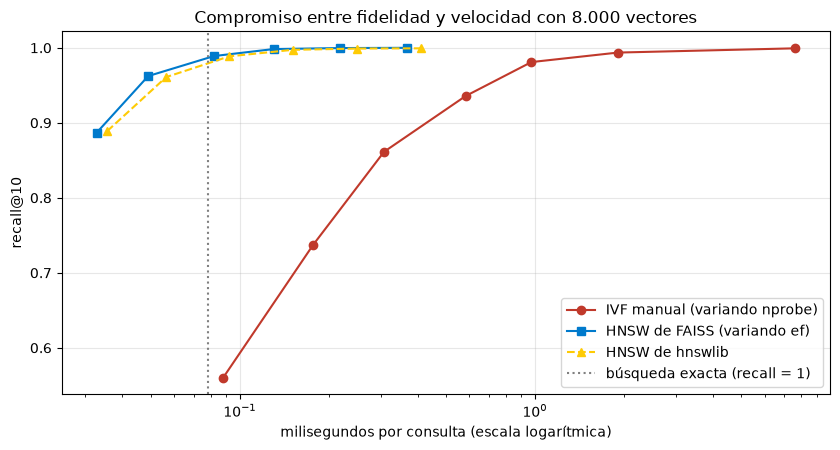

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(tabla_ivf["ms por consulta"], tabla_ivf["recall@10"], "o-", color="#C0392B", label="IVF manual (variando nprobe)")
ax.plot(tabla_hnsw["ms FAISS"], tabla_hnsw["recall FAISS"], "s-", color="#007ACC", label="HNSW de FAISS (variando ef)")
ax.plot(tabla_hnsw["ms hnswlib"], tabla_hnsw["recall hnswlib"], "^--", color="#FECB05", label="HNSW de hnswlib")
ax.axvline(latencia(lambda q: E @ q, Q), color="gray", ls=":", label="búsqueda exacta (recall = 1)")
ax.set_xscale("log")
ax.set_xlabel("milisegundos por consulta (escala logarítmica)")
ax.set_ylabel("recall@10")
ax.set_title("Compromiso entre fidelidad y velocidad con 8.000 vectores")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

HNSW cambia el panorama incluso a este tamaño: con `ef=20` ya recupera el 96 % de los vecinos exactos en 0,05 ms (la búsqueda exacta tarda 0,06 ms), y con `ef=80` llega a 0,998 en 0,13 ms. Subir `ef` suma latencia y recall, sin reconstruir el índice. Las dos implementaciones (FAISS y hnswlib) dan **el mismo recall** y latencias comparables: el algoritmo es el mismo, y lo que difiere es el código y las optimizaciones (FAISS es algo más rápido por consulta; hnswlib construye más rápido).

La gráfica resume la idea: a la **izquierda** y arriba está lo deseable (rápido y fiel). Nuestro IVF manual queda por detrás de HNSW en este conjunto (más lento a igual recall), algo frecuente en las pruebas con vectores en memoria; IVF gana en otros terrenos (construcción más barata, combinación con cuantización, poca memoria). Y a 8.000 vectores **la búsqueda exacta sigue siendo competitiva**: el ANN todavía no «paga».

<h3 style="color: #005C99;">4.3 ¿Cuándo vale la pena? Escala</h3>

Con 8.000 vectores la búsqueda exacta **gana**: es tan rápida que el costo fijo de cualquier índice no se compensa. La ventaja de un ANN aparece al crecer $N$. Para verlo necesitamos muchos más vectores de los que podemos embeber, así que usamos **vectores sintéticos** (256 dimensiones nominales, pero con una estructura de solo 12 dimensiones y 200 «temas», como la «dimensión intrínseca» baja de los embeddings reales), que imitan su estructura de agrupamiento pero **no sus detalles**: sirven para ver cómo escala cada método, no para predecir su recall exacto en tu corpus. Comparamos cuatro índices con 20.000, 100.000 y 300.000 vectores:

- **Flat**: búsqueda exacta (en FAISS).
- **HNSW** (`M=16`, `efSearch=128`).
- **IVF-Flat**: IVF con los vectores completos (`nprobe=16`).
- **IVF-PQ**: IVF con vectores **comprimidos** por cuantización de producto (sección 5) a 32 bytes cada uno.

In [13]:
def mezcla(n, d=256, latente=12, temas=200, ruido=0.4, semilla=SEED):
    """n vectores normalizados de d dimensiones que en realidad viven en un subespacio de `latente` dimensiones: una mezcla de gaussianas
    (una por 'tema') más un poco de ruido. Los embeddings reales también tienen una 'dimensión intrínseca' muy inferior a la nominal."""
    g = np.random.default_rng(semilla)
    base = np.linalg.qr(g.standard_normal((d, latente)))[0].T.astype("float32")
    centros = g.standard_normal((temas, latente)).astype("float32")
    Z = centros[g.integers(0, temas, n)] + ruido * g.standard_normal((n, latente)).astype("float32")
    X = Z @ base + 0.02 * g.standard_normal((n, d)).astype("float32")
    return X / np.linalg.norm(X, axis=1, keepdims=True)


CUANTIZADORES = []


def construir(nombre, X):
    """Construye un índice de FAISS y devuelve (índice, segundos de construcción)."""
    d, n = X.shape[1], len(X)
    t0 = time.perf_counter()
    faiss.omp_set_num_threads(HILOS)
    if nombre == "Flat":
        idx = faiss.IndexFlatIP(d)
    elif nombre == "HNSW":
        idx = faiss.IndexHNSWFlat(d, 16, faiss.METRIC_INNER_PRODUCT)
        idx.hnsw.efConstruction = 100
    else:
        cuant = faiss.IndexFlatIP(d)
        nlist = int(4 * np.sqrt(n))
        if nombre == "IVF-Flat":
            idx = faiss.IndexIVFFlat(cuant, d, nlist, faiss.METRIC_INNER_PRODUCT)
        else:
            idx = faiss.IndexIVFPQ(cuant, d, nlist, 32, 8, faiss.METRIC_INNER_PRODUCT)
        idx.cp.min_points_per_centroid = 20          # con menos datos que 39 por centroide FAISS avisa; 20 basta para este ejemplo
        idx.train(X)
        idx.nprobe = 16
        CUANTIZADORES.append(cuant)         # el cuantizador debe seguir vivo mientras exista el índice
    idx.add(X)
    faiss.omp_set_num_threads(1)
    if nombre == "HNSW":
        idx.hnsw.efSearch = 128
    return idx, time.perf_counter() - t0


filas = []
for n in [20_000, 100_000, 300_000]:
    X, QS = mezcla(n), mezcla(200, semilla=SEED + 1)
    exacto, _ = construir("Flat", X)
    verdad = exacto.search(QS, 10)[1]
    for nombre in ["Flat", "HNSW", "IVF-Flat", "IVF-PQ"]:
        idx, seg = (exacto, 0.0) if nombre == "Flat" else construir(nombre, X)
        memoria = len(faiss.serialize_index(idx)) / 1e6
        filas.append({"N": n, "índice": nombre, "construcción (s)": seg, "memoria (MB)": memoria,
                      "ms por consulta": latencia(lambda q: idx.search(q[None], 10), QS[:100]),
                      "recall@10": recall(idx.search(QS, 10)[1], verdad)})
    del X, exacto
escala = pd.DataFrame(filas)
display(escala.set_index(["N", "índice"]).round(3))

construcción (s)  memoria (MB)  ms por consulta  recall@10
N      índice                                                              
20000  Flat                 0.000        20.480            0.224      1.000
       HNSW                 0.747        23.364            0.061      0.990
       IVF-Flat             0.176        21.223            0.023      0.959
       IVF-PQ               0.626         1.645            0.023      0.450
100000 Flat                 0.000       102.400            1.814      1.000
       HNSW                 1.380       116.833            0.095      0.950
       IVF-Flat             1.806       104.505            0.047      0.922
       IVF-PQ               3.353         5.567            0.038      0.300
300000 Flat                 0.000       307.200            6.414      1.000
       HNSW                 3.899       350.484            0.129      0.874
       IVF-Flat             9.505       311.860            0.082      0.868
       IVF-PQ              10.130        14.522            0.071      0.228

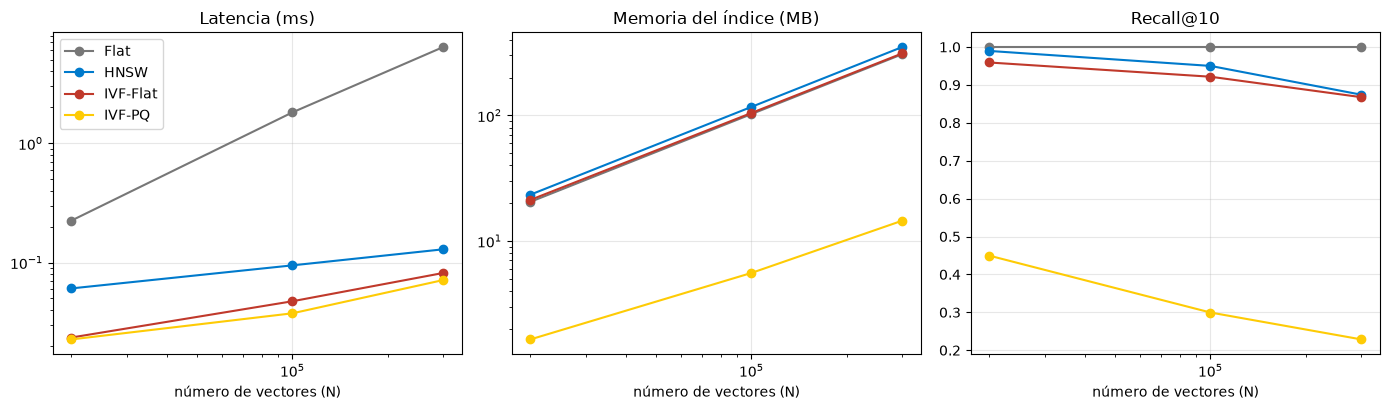

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2))
colores = {"Flat": "#777777", "HNSW": "#007ACC", "IVF-Flat": "#C0392B", "IVF-PQ": "#FECB05"}
for nombre, g in escala.groupby("índice"):
    for ax, col, titulo in zip(ejes, ["ms por consulta", "memoria (MB)", "recall@10"], ["Latencia (ms)", "Memoria del índice (MB)", "Recall@10"]):
        ax.plot(g["N"], g[col], "o-", color=colores[nombre], label=nombre)
        ax.set_title(titulo)
        ax.set_xscale("log")
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
        ax.set_xlabel("número de vectores (N)")
        ax.grid(alpha=0.3)
ejes[0].set_yscale("log")
ejes[1].set_yscale("log")
ejes[0].legend()
plt.tight_layout()
plt.show()

Aquí sí se ve el efecto de la escala:

- **Latencia.** La búsqueda exacta crece casi linealmente con N: de 0,22 ms con 20.000 vectores a 6,4 ms con 300.000. HNSW pasa de 0,06 a 0,13 ms (el doble con 15 veces más datos) e IVF-Flat de 0,02 a 0,08 ms. Con 300.000 vectores, HNSW es unas 50 veces más rápido que la búsqueda exacta.
- **Recall.** Cuesta: con parámetros fijos (`efSearch=128`, `nprobe=16`) el recall baja al crecer N (HNSW, de 0,99 a 0,87; IVF-Flat, de 0,96 a 0,87). Mantenerlo exige **subir** `ef` o `nprobe`, y por tanto la latencia: el ajuste no se hace una vez, se revisa al crecer.
- **Memoria.** El grafo de HNSW añade cerca de un 14 % sobre los vectores (350 MB contra 307 MB), IVF-Flat casi nada. **IVF-PQ** usa 20 veces menos memoria (14,5 MB), pero **sin reordenamiento** su recall es bajo (0,23 a 0,45): 32 bytes por vector son muy pocos para 256 dimensiones. Se usa con reordenamiento (sección 5).
- **Construcción.** HNSW tarda 4 s en 300.000 vectores y IVF 9 a 10 s (entrena k-means); crecen con N y es el costo de cada reindexado.

Recuerda que los datos son sintéticos: sirven para ver las **tendencias**, no para predecir cifras. Pero el mensaje es sólido: **a partir de cientos de miles de vectores, la búsqueda exacta deja de ser razonable para consultas interactivas, y el ANN exige ajustar parámetros que dependen de tus datos**.

<a id="cuantizacion"></a>
<h2 style="color: #007ACC;">5. Cuantización y reducción de dimensiones</h2>

El otro gran compromiso es la **memoria**. Un embedding de 1.536 dimensiones en `float32` ocupa 6 KB: 10 millones de fragmentos son 61 GB, antes de contar el índice. Hay dos palancas, que se pueden **combinar**:

| Técnica | Qué hace | Bytes por vector (1.536 dim.) |
|---|---|---|
| **Media precisión** (`float16`) | Guarda cada número con 2 bytes | 3.072 |
| **Cuantización escalar** (SQ8) | Cada dimensión se redondea a 256 niveles (1 byte) | 1.536 |
| **Cuantización de producto** (PQ) | Parte el vector en trozos y reemplaza cada trozo por el código del centroide más cercano de su propio diccionario | 96 a 192 |
| **Cuantización binaria** | Solo el signo de cada dimensión (1 bit); la distancia es de Hamming | 192 |
| **Vectores más cortos** (*Matryoshka*) | Algunos modelos (los `text-embedding-3` de OpenAI, Gemini, Nomic...) se entrenan para que **las primeras dimensiones** concentren la información: se truncan y se renormalizan | `4 × dimensiones` |

Todas pierden información, y por eso casi siempre se acompañan de **reordenamiento** (*rescoring*): se usa la versión **comprimida** (rápida y pequeña) para buscar los 100 mejores candidatos y la **completa** (que se lee de disco o de otra tabla) para ordenar solo esos 100. Es la misma idea de dos etapas del *reranking* del cuaderno 20, aplicada a los vectores. Medimos todo sobre los 8.000 embeddings reales:

In [15]:
def vecinos(S, k=10):
    """Los k mejores de cada fila de una matriz de puntajes."""
    cand = np.argpartition(-S, k, axis=1)[:, :k]
    return np.take_along_axis(cand, np.argsort(-np.take_along_axis(S, cand, 1), axis=1), 1)


def con_reordenamiento(candidatos, Q=Q, E=E, k=10):
    """Reordena los candidatos de cada consulta con los vectores completos y se queda con k."""
    salida = []
    for q, c in zip(Q, candidatos):
        c = np.asarray(c)
        salida.append(c[np.argsort(-(E[c] @ q))[:k]])
    return salida


D = E.shape[1]
filas = []


def registrar(nombre, bytes_por_vector, S=None, candidatos=None):
    """Recall@10 directo y con reordenamiento de los 100 mejores candidatos."""
    if S is not None:
        candidatos = np.argpartition(-S, 100, axis=1)[:, :100]
        directo = vecinos(S)
    else:
        directo = [c[:10] for c in candidatos]
    filas.append({"método": nombre, "bytes por vector": bytes_por_vector, "compresión": D * 4 / bytes_por_vector,
                  "recall@10": recall(directo, GT), "recall@10 con reordenamiento": recall(con_reordenamiento(candidatos), GT)})


registrar("float32 (referencia)", D * 4, S=Q @ E.T)
registrar("float16", D * 2, S=Q @ E.astype("float16").astype("float32").T)

minimo, rango = E.min(0), E.max(0) - E.min(0)
codigos = np.round((E - minimo) / rango * 255).astype("uint8")                 # un byte por dimensión
registrar("escalar int8", D, S=Q @ (codigos.astype("float32") / 255 * rango + minimo).T)

binarios = np.packbits(E > 0, axis=1)                                         # 1 bit por dimensión
signo = lambda M: 2 * np.unpackbits(M, axis=1, count=D).astype("float32") - 1
registrar("binaria (1 bit)", binarios.shape[1], S=signo(np.packbits(Q > 0, axis=1)) @ signo(binarios).T)    # equivale a la distancia de Hamming

for m in [192, 96]:
    pq = faiss.IndexPQ(D, m, 8, faiss.METRIC_INNER_PRODUCT)
    pq.pq.cp.min_points_per_centroid = 20
    pq.train(E)
    pq.add(E)
    registrar(f"PQ ({m} bytes)", m, candidatos=pq.search(Q, 100)[1])

if PRINCIPAL != "Ollama":                                                      # solo los modelos entrenados con la técnica Matryoshka
    for d_corta in [768, 512, 256, 128, 64]:
        corta = lambda M: M[:, :d_corta] / np.linalg.norm(M[:, :d_corta], axis=1, keepdims=True)
        registrar(f"truncado a {d_corta} dim.", d_corta * 4, S=corta(Q) @ corta(E).T)

cuantizacion = pd.DataFrame(filas).set_index("método")
display(cuantizacion.round(3))

,bytes por vector,compresión,recall@10,recall@10 con reordenamiento
método,,,,
float32 (referencia),6144,1.0,1.000,1.000
float16,3072,2.0,0.997,1.000
escalar int8,1536,4.0,0.995,0.999
binaria (1 bit),192,32.0,0.704,0.998
PQ (192 bytes),192,32.0,0.802,1.000
PQ (96 bytes),96,64.0,0.664,0.996
truncado a 768 dim.,3072,2.0,0.850,1.000
truncado a 512 dim.,2048,3.0,0.798,1.000
truncado a 256 dim.,1024,6.0,0.626,0.985


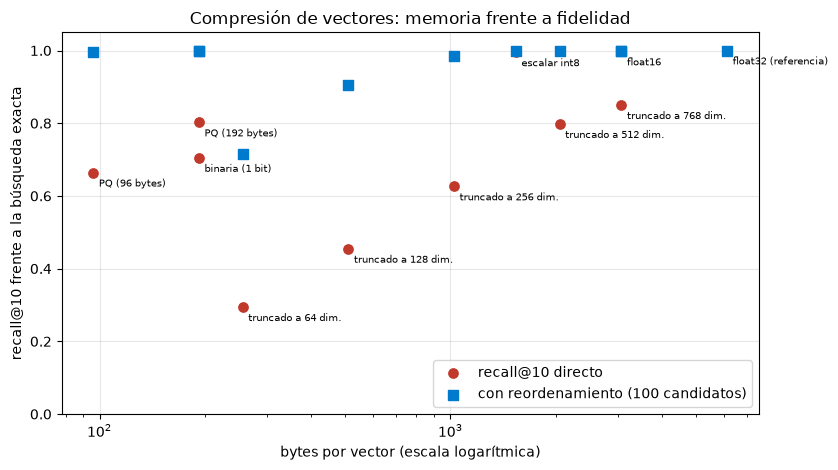

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.scatter(cuantizacion["bytes por vector"], cuantizacion["recall@10"], color="#C0392B", s=45, label="recall@10 directo", zorder=3)
ax.scatter(cuantizacion["bytes por vector"], cuantizacion["recall@10 con reordenamiento"], color="#007ACC", s=45, marker="s", label="con reordenamiento (100 candidatos)", zorder=3)
for nombre, f in cuantizacion.iterrows():
    ax.annotate(nombre, (f["bytes por vector"], f["recall@10"]), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("bytes por vector (escala logarítmica)")
ax.set_ylabel("recall@10 frente a la búsqueda exacta")
ax.set_ylim(0, 1.05)
ax.set_title("Compresión de vectores: memoria frente a fidelidad")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Lo que muestra la tabla:

- **Las compresiones suaves casi no cuestan nada**: `float16` (2 veces menos memoria) y `int8` (4 veces) conservan 0,995 o más del recall sin reordenar. Son un buen punto de partida.
- **La cuantización binaria** ocupa 192 bytes (32 veces menos) y por sí sola recupera el 70 % de los vecinos, pero con **reordenamiento de 100 candidatos** llega a 0,998. **PQ** también: 192 bytes pasan de 0,80 a 1,00, y con 96 bytes (64 veces menos) de 0,66 a 0,996. Es la combinación que usan los motores grandes: vectores comprimidos en memoria para buscar, y los completos en disco para reordenar unos pocos.
- **Truncar dimensiones** pierde más: a 512 dimensiones el recall directo es 0,80 y a 128, 0,45; el reordenamiento lo recupera hasta 256 dimensiones (0,985) pero no con 64 (0,72). Ojo con **qué se compara**: este recall mide la fidelidad a los **vecinos de los vectores completos**, y un vector truncado es una representación **distinta**, no una copia degradada: lo que pierda en relevancia real (sobre tareas de recuperación) suele ser menos que lo que muestra esta tabla, y la forma de saberlo es evaluar con tus preguntas, como en el cuaderno 20.
- Todo esto exige guardar también **los vectores completos** (en disco o en otra tabla) para reordenar, y algunos modelos no se pueden truncar (solo los entrenados con la técnica Matryoshka).

<a id="bases-de-datos"></a>
<h2 style="color: #007ACC;">6. Bases de datos vectoriales en la práctica</h2>

Hasta aquí, el motor. Una **base de datos vectorial** envuelve un índice como los anteriores con lo que una aplicación necesita: almacenamiento de los vectores **y de sus metadatos**, filtros, inserciones y borrados, persistencia y, según el caso, servidor, replicación y particionado. Las opciones se ordenan por cómo se **despliegan**:

| Forma | Qué es | Ejemplos |
|---|---|---|
| **Biblioteca** | Código que corre dentro de tu proceso; tú gestionas datos, metadatos y persistencia | FAISS, hnswlib, ScaNN, USearch, Annoy |
| **Embebida** | Una base de datos completa que corre dentro de tu proceso, guardando en archivos locales (como SQLite) | Chroma, LanceDB, Qdrant (modo local), Milvus Lite |
| **Servidor** | Un servicio al que te conectas por red, con replicación y control de acceso | Qdrant, Milvus, Weaviate, Chroma (servidor), Vespa |
| **Extensión de una base de datos existente** | Un tipo de dato y un índice vectorial dentro de una base de datos que ya usas | **pgvector** (PostgreSQL), Elasticsearch y OpenSearch, MongoDB Atlas, Redis, SQLite (`sqlite-vec`), DuckDB |
| **Servicio gestionado** | El proveedor opera el servidor y cobra por uso | Pinecone, Qdrant Cloud, Weaviate Cloud, Zilliz Cloud, los servicios de las nubes (sección 10) |

Probamos cinco herramientas que corren **en tu equipo sin servidor**: **FAISS** (la biblioteca, con HNSW), **Chroma**, **Qdrant** (en modo local, pensado para pruebas), **LanceDB** y **Milvus Lite**, además de la búsqueda exacta con NumPy como referencia. Cada una tiene su propio API, así que escribimos un *adaptador* con las mismas seis operaciones (`crear`, `insertar`, `buscar` con filtro, `borrar`, `contar`, `reabrir`) para poder compararlas con el mismo código. Lo interesante de esa capa es **lo que hay que traducir**: el **mismo filtro**, que escribimos una sola vez, se expresa de cuatro maneras distintas.

In [17]:
import pickle

import chromadb
import lancedb
from lancedb.index import IvfHnswSq
from pymilvus import MilvusClient
from qdrant_client import QdrantClient, models


def cumple(meta, filtro):
    """¿Los metadatos de un documento cumplen el filtro? (se usa donde la herramienta no sabe filtrar por sí misma)"""
    return ((filtro.get("tema") is None or meta["tema"] == filtro["tema"]) and
            (filtro.get("largo_min") is None or meta["largo"] >= filtro["largo_min"]))


class Adaptador:
    """Interfaz común mínima para comparar herramientas: crear, insertar, buscar (con filtro), borrar, contar y reabrir."""
    nombre = "base"

    def __init__(self, ruta):
        self.ruta = Path(ruta)
        shutil.rmtree(self.ruta, ignore_errors=True)
        self.ruta.mkdir(parents=True)

    def tamano_disco(self):
        return sum(f.stat().st_size for f in self.ruta.rglob("*") if f.is_file())

    def guardar(self):
        pass


class NumpyExacto(Adaptador):
    nombre = "NumPy (exacta)"

    def crear(self, dim):
        self.V, self.meta, self.ids = np.zeros((0, dim), "float32"), [], np.zeros(0, int)

    def insertar(self, ids, vectores, metadatos):
        self.V, self.ids, self.meta = np.vstack([self.V, vectores]), np.concatenate([self.ids, ids]), self.meta + list(metadatos)

    def buscar(self, q, k=10, filtro=None):
        s = self.V @ q
        if filtro:
            s = np.where([cumple(m, filtro) for m in self.meta], s, -np.inf)
        return [int(i) for i in self.ids[np.argsort(-s)[:k]]]

    def borrar(self, ids):
        mantener = ~np.isin(self.ids, ids)
        self.V, self.ids, self.meta = self.V[mantener], self.ids[mantener], [m for m, c in zip(self.meta, mantener) if c]

    def contar(self):
        return len(self.ids)

    def guardar(self):
        with open(self.ruta / "datos.pkl", "wb") as f:
            pickle.dump((self.V, self.ids, self.meta), f)

    def reabrir(self):
        with open(self.ruta / "datos.pkl", "rb") as f:
            self.V, self.ids, self.meta = pickle.load(f)


class FaissHNSW(Adaptador):
    nombre = "FAISS (HNSW)"

    def crear(self, dim):
        self.idx = faiss.IndexHNSWFlat(dim, 16, faiss.METRIC_INNER_PRODUCT)
        self.idx.hnsw.efConstruction, self.idx.hnsw.efSearch = 200, 100
        self.meta, self._permitidos = [], {}

    def insertar(self, ids, vectores, metadatos):
        self.idx.add(vectores)                      # FAISS no guarda metadatos: los guardamos aparte, en el mismo orden
        self.meta += list(metadatos)

    def buscar(self, q, k=10, filtro=None):
        params = None
        if filtro:                                  # filtro DENTRO de la búsqueda: el grafo solo acepta los vectores permitidos
            clave = tuple(sorted(filtro.items()))
            if clave not in self._permitidos:
                self._permitidos[clave] = faiss.IDSelectorBatch(np.array([i for i, m in enumerate(self.meta) if cumple(m, filtro)], dtype="int64"))
            params = faiss.SearchParametersHNSW()
            params.sel = self._permitidos[clave]
            params.efSearch = 100
        _, I = self.idx.search(q[None], k, params=params)
        return [int(i) for i in I[0] if i >= 0]

    def borrar(self, ids):
        raise NotImplementedError("HNSW de FAISS no permite borrar: hay que reconstruir el índice")

    def contar(self):
        return self.idx.ntotal

    def guardar(self):
        faiss.write_index(self.idx, str(self.ruta / "indice.faiss"))
        with open(self.ruta / "meta.pkl", "wb") as f:
            pickle.dump(self.meta, f)

    def reabrir(self):
        self.idx = faiss.read_index(str(self.ruta / "indice.faiss"))
        with open(self.ruta / "meta.pkl", "rb") as f:
            self.meta = pickle.load(f)
        self._permitidos = {}


class ChromaDB(Adaptador):
    nombre = "Chroma"

    def crear(self, dim):
        self.cliente = chromadb.PersistentClient(path=str(self.ruta))
        self.col = self.cliente.create_collection("docs", embedding_function=None, configuration={
            "hnsw": {"space": "cosine", "ef_construction": 200, "max_neighbors": 16, "ef_search": 100}})

    @staticmethod
    def _donde(filtro):
        cond = ([{"tema": filtro["tema"]}] if filtro.get("tema") else []) + ([{"largo": {"$gte": filtro["largo_min"]}}] if filtro.get("largo_min") else [])
        return cond[0] if len(cond) == 1 else {"$and": cond}

    def insertar(self, ids, vectores, metadatos):
        self.col.add(ids=[str(i) for i in ids], embeddings=vectores.tolist(), metadatas=list(metadatos))

    def buscar(self, q, k=10, filtro=None):
        r = self.col.query(query_embeddings=[q.tolist()], n_results=k, where=self._donde(filtro) if filtro else None, include=[])
        return [int(i) for i in r["ids"][0]]

    def borrar(self, ids):
        self.col.delete(ids=[str(i) for i in ids])

    def contar(self):
        return self.col.count()

    def reabrir(self):
        self.cliente = chromadb.PersistentClient(path=str(self.ruta))
        self.col = self.cliente.get_collection("docs", embedding_function=None)


class QdrantDB(Adaptador):
    nombre = "Qdrant (modo local)"

    def crear(self, dim):
        self.cliente = QdrantClient(path=str(self.ruta))
        self.cliente.create_collection("docs", vectors_config=models.VectorParams(size=dim, distance=models.Distance.COSINE),
                                       hnsw_config=models.HnswConfigDiff(m=16, ef_construct=200))

    @staticmethod
    def _filtro(filtro):
        cond = ([models.FieldCondition(key="tema", match=models.MatchValue(value=filtro["tema"]))] if filtro.get("tema") else []) + \
               ([models.FieldCondition(key="largo", range=models.Range(gte=filtro["largo_min"]))] if filtro.get("largo_min") else [])
        return models.Filter(must=cond)

    def insertar(self, ids, vectores, metadatos):
        self.cliente.upsert("docs", points=[models.PointStruct(id=int(i), vector=v.tolist(), payload=m) for i, v, m in zip(ids, vectores, metadatos)])

    def buscar(self, q, k=10, filtro=None):
        r = self.cliente.query_points("docs", query=q.tolist(), limit=k, query_filter=self._filtro(filtro) if filtro else None, with_payload=False)
        return [p.id for p in r.points]

    def borrar(self, ids):
        self.cliente.delete("docs", points_selector=models.PointIdsList(points=[int(i) for i in ids]))

    def contar(self):
        return self.cliente.count("docs").count

    def reabrir(self):
        self.cliente.close()
        self.cliente = QdrantClient(path=str(self.ruta))


class LanceDB(Adaptador):
    def __init__(self, ruta, indice=None):
        super().__init__(ruta)
        self.indice = indice
        self.nombre = "LanceDB" + (f" ({indice})" if indice else " (sin índice)")

    def crear(self, dim):
        self.db = lancedb.connect(str(self.ruta))
        self.tabla = None

    @staticmethod
    def _donde(filtro):
        return " AND ".join(([f"tema = '{filtro['tema']}'"] if filtro.get("tema") else []) + ([f"largo >= {filtro['largo_min']}"] if filtro.get("largo_min") else []))

    def insertar(self, ids, vectores, metadatos):
        filas = [{"id": int(i), "vector": v, **m} for i, v, m in zip(ids, vectores, metadatos)]
        if self.tabla is None:
            self.tabla = self.db.create_table("docs", data=filas)
        else:
            self.tabla.add(filas)

    def construir_indice(self):
        if self.indice == "IVF_HNSW_SQ":
            self.tabla.create_index("vector", config=IvfHnswSq(distance_type="cosine", num_partitions=4, m=16, ef_construction=200))

    def buscar(self, q, k=10, filtro=None):
        consulta = self.tabla.search(q).metric("cosine").limit(k)
        if self.indice:
            consulta = consulta.ef(100) if hasattr(consulta, "ef") else consulta
        if filtro:
            consulta = consulta.where(self._donde(filtro), prefilter=True)
        return [r["id"] for r in consulta.to_list()]

    def borrar(self, ids):
        self.tabla.delete(f"id IN ({', '.join(str(int(i)) for i in ids)})")

    def contar(self):
        return self.tabla.count_rows()

    def reabrir(self):
        self.db = lancedb.connect(str(self.ruta))
        self.tabla = self.db.open_table("docs")


class MilvusLite(Adaptador):
    nombre = "Milvus Lite"

    def crear(self, dim):
        self.cliente = MilvusClient(str(self.ruta / "milvus.db"))
        self.cliente.create_collection("docs", dimension=dim, metric_type="COSINE", id_type="int", auto_id=False)

    @staticmethod
    def _expr(filtro):
        return " and ".join(([f'tema == "{filtro["tema"]}"'] if filtro.get("tema") else []) + ([f'largo >= {filtro["largo_min"]}'] if filtro.get("largo_min") else []))

    def insertar(self, ids, vectores, metadatos):
        self.cliente.insert("docs", [{"id": int(i), "vector": v.tolist(), **m} for i, v, m in zip(ids, vectores, metadatos)])

    def buscar(self, q, k=10, filtro=None):
        r = self.cliente.search("docs", data=[q.tolist()], limit=k, filter=self._expr(filtro) if filtro else "", output_fields=[])
        return [h["id"] for h in r[0]]

    def borrar(self, ids):
        self.cliente.delete("docs", ids=[int(i) for i in ids])

    def contar(self):
        return self.cliente.get_collection_stats("docs")["row_count"]

    def reabrir(self):
        self.cliente.close()
        self.cliente = MilvusClient(str(self.ruta / "milvus.db"))

In [18]:
FILTRO = {"tema": "comp", "largo_min": 1000}          # los mensajes de computación de al menos 1.000 caracteres
print("Chroma  :", ChromaDB._donde(FILTRO))
print("Qdrant  :", QdrantDB._filtro(FILTRO).model_dump(exclude_none=True))
print("LanceDB :", LanceDB._donde(FILTRO))
print("Milvus  :", MilvusLite._expr(FILTRO))

Chroma  : {'$and': [{'tema': 'comp'}, {'largo': {'$gte': 1000}}]}
Qdrant  : {'must': [{'key': 'tema', 'match': {'value': 'comp'}}, {'key': 'largo', 'range': {'gte': 1000.0}}]}
LanceDB : tema = 'comp' AND largo >= 1000
Milvus  : tema == "comp" and largo >= 1000


Chroma usa un diccionario con operadores (`$and`, `$gte`), Qdrant objetos tipados, LanceDB y Milvus una expresión de texto estilo SQL. Es una de las razones por las que las abstracciones de los frameworks (sección 9) **no son transparentes**: el filtro sigue siendo propio de cada herramienta.

Ahora el banco de pruebas. Para cada herramienta: (1) **insertar** los 8.000 vectores con sus metadatos, en lotes de 1.000; (2) buscar con 100 de las consultas y medir **latencia** y **recall@10** frente a la búsqueda exacta; (3) repetir con el **filtro** y comparar con la búsqueda exacta *dentro del subconjunto filtrado*; (4) **guardar, cerrar y reabrir**, midiendo el tamaño en disco; y (5) **borrar** 100 documentos y comprobar que ya no aparecen. Las herramientas se usan con parámetros HNSW equivalentes (`M=16`, `ef` de construcción 200 y de búsqueda 100) cuando los exponen.

In [19]:
METAS = DOCS[["tema", "largo"]].to_dict("records")
mascara = np.array([cumple(m, FILTRO) for m in METAS])
GT_F = vecinos(np.where(mascara, Q @ E.T, -np.inf))                 # los vecinos exactos dentro del subconjunto filtrado
NB = 100                                                              # consultas por herramienta (Milvus Lite y Qdrant local son lentos: cada consulta cuenta)
print(f"El filtro deja {mascara.sum()} de {len(E)} documentos ({mascara.mean():.0%})")


def probar(A, lote=1000):
    """Ejecuta las cinco pruebas sobre un adaptador y devuelve una fila de resultados."""
    r = {"herramienta": A.nombre}
    t0 = time.perf_counter()
    A.crear(E.shape[1])
    for i in range(0, len(E), lote):
        A.insertar(np.arange(i, min(i + lote, len(E))), E[i:i + lote], METAS[i:i + lote])
    if hasattr(A, "construir_indice"):
        A.construir_indice()
    r["inserción (s)"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = [A.buscar(q, 10) for q in Q[:NB]]
    r["ms por consulta"] = (time.perf_counter() - t0) / NB * 1000
    r["recall@10"] = recall(pred, GT[:NB])
    t0 = time.perf_counter()
    pred_f = [A.buscar(q, 10, FILTRO) for q in Q[:NB]]
    r["ms con filtro"] = (time.perf_counter() - t0) / NB * 1000
    r["recall@10 con filtro"] = recall(pred_f, GT_F[:NB])
    r["resultados con filtro"] = np.mean([len(p) for p in pred_f])
    r["cumplen el filtro"] = np.mean([mascara[i] for p in pred_f for i in p])

    A.guardar()
    r["disco (MB)"] = A.tamano_disco() / 1e6
    t0 = time.perf_counter()
    A.reabrir()
    r["reapertura (s)"] = time.perf_counter() - t0
    r["intacta tras reabrir"] = A.contar() == len(E) and A.buscar(Q[0], 10) == pred[0]
    try:
        A.borrar(np.arange(100))
        r["borrado correcto"] = A.contar() == len(E) - 100 and not any(i < 100 for q in Q[:30] for i in A.buscar(q, 10))
    except NotImplementedError:
        r["borrado correcto"] = "no soporta"
    return r


HERRAMIENTAS = [NumpyExacto(DIRECTORIO / "numpy"), FaissHNSW(DIRECTORIO / "faiss"), ChromaDB(DIRECTORIO / "chroma"), QdrantDB(DIRECTORIO / "qdrant"),
                LanceDB(DIRECTORIO / "lance_plano"), LanceDB(DIRECTORIO / "lance_hnsw", "IVF_HNSW_SQ"), MilvusLite(DIRECTORIO / "milvus")]
banco = pd.DataFrame([probar(A) for A in HERRAMIENTAS]).set_index("herramienta")
display(banco.round(3))

El filtro deja 468 de 8000 documentos (6%)


,inserción (s),ms por consulta,recall@10,ms con filtro,recall@10 con filtro,resultados con filtro,cumplen el filtro,disco (MB),reapertura (s),intacta tras reabrir,borrado correcto
herramienta,,,,,,,,,,,
NumPy (exacta),0.017,0.173,1.000,0.958,1.000,10.00,1.0,49.356,0.018,True,True
FAISS (HNSW),1.641,0.156,0.999,0.171,0.551,8.81,1.0,50.444,0.012,True,no soporta
Chroma,1.803,0.621,0.999,5.449,1.000,10.00,1.0,60.934,0.002,True,True
Qdrant (modo local),125.943,20.725,0.997,65.099,1.000,10.00,1.0,114.979,0.451,True,True
LanceDB (sin índice),0.089,6.984,0.998,7.698,1.000,10.00,1.0,49.198,0.001,True,True
LanceDB (IVF_HNSW_SQ),0.225,2.074,0.996,2.531,0.990,10.00,1.0,62.762,0.001,True,True
Milvus Lite,2.023,406.694,0.999,481.546,1.000,10.00,1.0,49.651,0.005,True,True


Con 8.000 vectores **casi no hay diferencias de recall** (0,996 a 1,000 en todas), así que las diferencias están en el resto. Lo que enseña la tabla:

- **No gana la base de datos más sofisticada, sino la búsqueda más simple.** A este tamaño, NumPy (0,17 ms por consulta) y FAISS (0,16 ms) están por delante de las bases de datos, que añaden almacenamiento, metadatos y transacciones. Es el precio de las funciones, y a esta escala es pequeño (Chroma, 0,6 ms; LanceDB con índice, 2 ms).
- **Los modos locales de las bases de datos de servidor no miden a sus servidores.** **Qdrant en modo local** es una implementación en Python para pruebas: no usa HNSW (la consulta tarda 21 ms) e inserta lentamente (**126 segundos** para 8.000 vectores). **Milvus Lite**, pensado para prototipos, tardó 407 ms por consulta. Ninguna de las dos cifras describe a Qdrant o Milvus en producción (servidor, índice HNSW u otros); compáralas con un servidor propio antes de decidir.
- **El filtro separa a las herramientas.** Con un filtro que deja el 6 % de los documentos, **FAISS devolvió solo 8,8 de 10 resultados y recuperó el 55 %** de los vecinos correctos: filtrar dentro de un HNSW sin que el índice esté preparado para ello pierde recall (lo exploramos en la sección 7). Las demás herramientas dieron 10 resultados y recall entre 0,99 y 1,0, con costos distintos (de 2,5 ms de LanceDB con índice a 5 ms de Chroma y 65 ms de Qdrant local).
- **FAISS no borra** en HNSW (hay que reconstruir), y tampoco guarda metadatos: los guardamos aparte. Es una **biblioteca**: te da el índice y tú construyes el resto.
- **Persistencia y borrado funcionan en todas** (menos el borrado de FAISS): reabrir tarda menos de un segundo y el contenido queda intacto.
- **Espacio en disco**: los datos crudos ocupan 49 MB; Chroma añade un 23 % (su base de metadatos y el índice), LanceDB con HNSW un 27 % y Qdrant local más del doble (115 MB).

<a id="filtros"></a>
<h2 style="color: #007ACC;">7. Filtros por metadatos</h2>

En un RAG real casi ninguna consulta es «los 10 vecinos más cercanos de **todo**»: es «los más cercanos entre los documentos **vigentes**, de **esta área**, que **este usuario puede ver**» (cuaderno 20, secciones 6.3 y 9.2). Combinar similitud vectorial y filtros parece trivial y es uno de los problemas técnicos más difíciles de las bases de datos vectoriales. Hay tres estrategias:

| Estrategia | Cómo funciona | Problema |
|---|---|---|
| **Post-filtro** | Buscar los $k \cdot m$ más cercanos y **después** descartar los que no cumplen el filtro | Si el filtro es muy restrictivo, no sobrevive ninguno: el resultado trae **menos de $k$** (o ninguno) |
| **Pre-filtro** | Aplicar el filtro **primero** y buscar solo entre los que cumplen, normalmente por fuerza bruta | Exacto, pero el costo crece con el tamaño del subconjunto |
| **Filtro dentro del índice** | El índice solo **acepta** los vectores que cumplen el filtro mientras navega | En un grafo HNSW, descartar nodos **rompe los caminos**: el recorrido se queda atrapado y se pierde recall |

Lo comprobamos con el índice HNSW de FAISS de la sección 4 y cuatro filtros de selectividad decreciente (del 100 % de los documentos a cerca del 1 %). Para cada estrategia medimos el recall frente a la búsqueda exacta **dentro del subconjunto**, y cuántos resultados de 10 se devuelven.

In [20]:
GRUPOS, LARGOS = DOCS.grupo.values, DOCS.largo.values
FILTROS = {
    "sin filtro": np.ones(len(E), bool),
    "tema = comp": DOCS.tema.values == "comp",
    "grupo = sci.space": GRUPOS == "sci.space",
    "grupo = sci.space y largo ≥ 1500": (GRUPOS == "sci.space") & (LARGOS >= 1500),
}
print({nombre: f"{m.mean():.1%} ({m.sum()} docs)" for nombre, m in FILTROS.items()})

hnsw.hnsw.efSearch = 100


def post_filtro(mascara, factor):
    """Busca 10 × factor vecinos y descarta los que no cumplen el filtro."""
    I = hnsw.search(Q, 10 * factor)[1]
    return [[j for j in fila if mascara[j]][:10] for fila in I]


def en_el_grafo(mascara, ef):
    """El índice solo acepta los vectores permitidos (IDSelector) mientras recorre el grafo."""
    params = faiss.SearchParametersHNSW()
    params.sel = faiss.IDSelectorBatch(np.where(mascara)[0].astype("int64"))
    params.efSearch = ef
    return [[j for j in fila if j >= 0] for fila in hnsw.search(Q, 10, params=params)[1]]


def prefiltro_exacto(mascara):
    """Primero el filtro, después fuerza bruta solo sobre los que cumplen."""
    ids = np.where(mascara)[0]
    return [ids[f] for f in vecinos(Q @ E[ids].T, min(10, len(ids)))]


ESTRATEGIAS = {"post-filtro (×1)": lambda m: post_filtro(m, 1), "post-filtro (×10)": lambda m: post_filtro(m, 10), "post-filtro (×50)": lambda m: post_filtro(m, 50),
               "en el grafo (ef=100)": lambda m: en_el_grafo(m, 100), "en el grafo (ef=1000)": lambda m: en_el_grafo(m, 1000), "prefiltro exacto": prefiltro_exacto}
filas = []
for nombre_f, m in FILTROS.items():
    verdad = [list(v) for v in vecinos(np.where(m, Q @ E.T, -np.inf), 10)]
    for nombre_e, estrategia in ESTRATEGIAS.items():
        t0 = time.perf_counter()
        pred = estrategia(m)
        filas.append({"filtro": nombre_f, "selectividad": m.mean(), "estrategia": nombre_e, "recall@10": recall(pred, verdad),
                      "resultados (de 10)": np.mean([len(p) for p in pred]), "ms por consulta": (time.perf_counter() - t0) / len(Q) * 1000})
filtrado = pd.DataFrame(filas)
display(filtrado.pivot(index="estrategia", columns="filtro", values="recall@10").reindex(list(ESTRATEGIAS))[list(FILTROS)].round(2))
print("Resultados devueltos por consulta (de 10):")
display(filtrado.pivot(index="estrategia", columns="filtro", values="resultados (de 10)").reindex(list(ESTRATEGIAS))[list(FILTROS)].round(1))

{'sin filtro': '100.0% (8000 docs)', 'tema = comp': '25.1% (2009 docs)', 'grupo = sci.space': '5.3% (425 docs)', 'grupo = sci.space y largo ≥ 1500': '0.9% (73 docs)'}


filtro,sin filtro,tema = comp,grupo = sci.space,grupo = sci.space y largo ≥ 1500
estrategia,,,,
post-filtro (×1),1.0,0.28,0.06,0.01
post-filtro (×10),1.0,0.46,0.21,0.08
post-filtro (×50),1.0,0.64,0.52,0.23
en el grafo (ef=100),1.0,0.67,0.61,0.35
en el grafo (ef=1000),1.0,0.97,0.99,0.93
prefiltro exacto,1.0,1.00,1.00,1.00


Resultados devueltos por consulta (de 10):


filtro,sin filtro,tema = comp,grupo = sci.space,grupo = sci.space y largo ≥ 1500
estrategia,,,,
post-filtro (×1),10.0,2.8,0.6,0.1
post-filtro (×10),10.0,4.6,2.1,0.8
post-filtro (×50),10.0,7.5,6.1,2.4
en el grafo (ef=100),10.0,9.9,9.9,5.9
en el grafo (ef=1000),10.0,10.0,10.0,10.0
prefiltro exacto,10.0,10.0,10.0,10.0


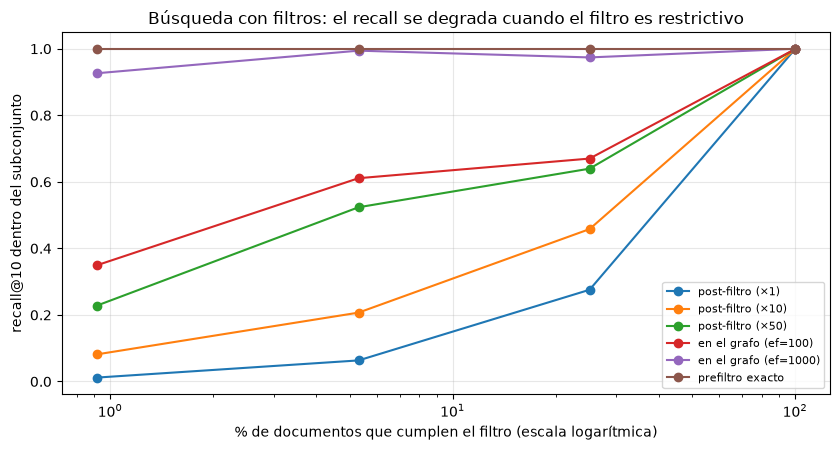

In [21]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for nombre_e in ESTRATEGIAS:
    g = filtrado[filtrado.estrategia == nombre_e].sort_values("selectividad")
    ax.plot(g["selectividad"] * 100, g["recall@10"], "o-", label=nombre_e)
ax.set_xscale("log")
ax.set_xlabel("% de documentos que cumplen el filtro (escala logarítmica)")
ax.set_ylabel("recall@10 dentro del subconjunto")
ax.set_title("Búsqueda con filtros: el recall se degrada cuando el filtro es restrictivo")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

Tres lecciones de la tabla:

1. **El post-filtro colapsa cuando el filtro restringe.** Con un filtro del 25 % de los documentos, pedir 10 y filtrar devuelve 2,8 resultados por consulta; con uno del 5 %, 0,6; con uno del 1 %, 0,1. Pedir más candidatos ayuda (×50 llega a 7,5, 6,1 y 2,4 resultados) pero no resuelve el problema y encarece la búsqueda. Es lo que le pasó al almacén FAISS de LangChain en la sección 9.
2. **Filtrar dentro del grafo funciona solo si se compensa con más exploración.** Con `ef=100` devuelve casi siempre 10 resultados (5,9 con el filtro del 1 %), pero el recall cae a 0,35 en el filtro más estricto; con `ef=1000` se recupera (0,93 a 0,99), a costa de explorar mucho más. Cuanto más restrictivo el filtro, más `ef` hace falta.
3. **El pre-filtro exacto es perfecto y barato justo donde lo anterior falla**: con 73 documentos que cumplen el filtro, comparar con 73 vectores es trivial. La mejor estrategia **depende de la selectividad**: grafo si el filtro deja muchos documentos, fuerza bruta sobre el subconjunto si deja pocos. Los motores serios (Qdrant, Weaviate...) eligen la estrategia **automáticamente** con una estimación de la cardinalidad del filtro; una biblioteca como FAISS te deja esa decisión a ti.

Las bases de datos vectoriales resuelven esto de formas distintas, y es **uno de los criterios que más conviene mirar al elegir**. Lo que documentan los proyectos:

- **Qdrant** construye el grafo HNSW pensando en los filtros: añade enlaces según los valores de los campos indexados (*payload indexes*) y elige la estrategia según la selectividad (grafo si el filtro es amplio, índice del campo y fuerza bruta si es muy restrictivo).
- **Weaviate** usa un recorrido del grafo con filtro y, para filtros muy restrictivos, cae a búsqueda exacta sobre los candidatos; versiones recientes incorporan el algoritmo **ACORN**.
- **Elasticsearch/OpenSearch** (Lucene) aplican el filtro durante la navegación del grafo.
- **pgvector** hacía post-filtro dentro del índice (el problema de la tabla de arriba); las versiones recientes añaden **escaneos iterativos** que siguen buscando hasta reunir $k$ resultados que cumplan el filtro.
- **Milvus** y **Pinecone** evalúan el filtro como una máscara de bits o un índice de metadatos durante la búsqueda.
- **Chroma** y **LanceDB** permiten elegir entre pre-filtro (exacto sobre el subconjunto, que es lo que vimos) y post-filtro.

Reglas útiles: (1) **indexa los campos** por los que filtras; (2) prueba con **tus** filtros más restrictivos y mide cuántos resultados vuelven; (3) si una dimensión de filtro tiene pocos documentos por valor (un inquilino, un usuario), una **colección o partición por valor** puede ser mejor que un filtro.

<a id="busqueda-hibrida"></a>
<h2 style="color: #007ACC;">8. Búsqueda híbrida dentro de la base de datos</h2>

En el cuaderno 20 construimos a mano la búsqueda híbrida (BM25 y embeddings, fusionados con RRF). En producción, **la base de datos la hace por ti**, y es uno de los motivos para elegir una u otra: ¿tiene búsqueda por palabras (BM25 o *full-text search*), vectores dispersos, y fusión integrada? Con **LanceDB** lo probamos con las tres variantes sobre nuestros 8.000 documentos: **densa** (vectores), **por palabras** (índice de texto completo) e **híbrida** (fusión RRF), con dos tipos de consultas:

- **Consultas naturales**: el comienzo de otro mensaje (250 caracteres). Medimos la **pureza de grupo@10**: de los 10 resultados, cuántos son del mismo grupo de discusión que la consulta.
- **Consultas de «palabra rara»**: una sola palabra que aparece en un único documento (un nombre, una sigla, un término técnico). Medimos si ese documento aparece entre los 10 primeros (**acierto@10**). Es el caso donde la búsqueda semántica tiene problemas, porque una palabra rara no tiene un «significado» para el embedding.

In [22]:
from lancedb.rerankers import RRFReranker

db_h = lancedb.connect(str(DIRECTORIO / "hibrido"))
tabla_h = db_h.create_table("docs", data=[{"id": i, "vector": E[i], "texto": DOCS.texto[i], "grupo": DOCS.grupo[i]} for i in range(len(E))])
tabla_h.create_fts_index("texto", replace=True)                    # índice de texto completo (BM25)
limpio = lambda t: re.sub(r"[^\w\s]", " ", t)                       # el analizador de consultas del índice de texto no admite signos especiales


def buscar_h(modo, vector, texto, k=10):
    if modo == "densa":
        r = tabla_h.search(vector).metric("cosine").limit(k)
    elif modo == "palabras":
        r = tabla_h.search(limpio(texto), query_type="fts").limit(k)
    else:
        r = tabla_h.search(query_type="hybrid").vector(vector).text(limpio(texto)).metric("cosine").rerank(RRFReranker()).limit(k)
    return [x["id"] for x in r.to_list()]


# A. consultas naturales
textos_q = CONSULTAS.texto.str.slice(0, 250).tolist()
filas = {}
for modo in ["densa", "palabras", "híbrida"]:
    pred = [buscar_h(modo, Q[i], textos_q[i]) for i in range(100)]
    filas[modo] = {"pureza de grupo@10": np.mean([(GRUPOS[p] == CONSULTAS.grupo[i]).mean() if len(p) else 0 for i, p in enumerate(pred)])}

# B. consultas de una palabra rara (aparece en un solo documento)
df = Counter(w for t in DOCS.texto for w in set(re.findall(r"[a-z]{6,12}", t.lower())))
raras = {}
for i, t in enumerate(DOCS.texto):
    for w in dict.fromkeys(re.findall(r"[a-z]{6,12}", t.lower())):
        if df[w] == 1 and w not in raras.values():
            raras[i] = w
            break
objetivos = list(raras)[:100]
QR = embeber([raras[i] for i in objetivos])
for modo in ["densa", "palabras", "híbrida"]:
    pred = [buscar_h(modo, QR[j], raras[i]) for j, i in enumerate(objetivos)]
    filas[modo]["acierto@10 con palabra rara"] = np.mean([i in p for i, p in zip(objetivos, pred)])
resultado_hibrido = pd.DataFrame(filas).T
print("Ejemplos de palabras raras:", [raras[i] for i in objetivos[:8]])
display(resultado_hibrido.round(3))

Ejemplos de palabras raras: ['evidentiary', 'identically', 'sightedness', 'hyperdermic', 'discern', 'agreements', 'illuminatti', 'raistlin']


,pureza de grupo@10,acierto@10 con palabra rara
densa,0.717,0.20
palabras,0.480,0.89
híbrida,0.619,0.83


El resultado no es «la híbrida siempre gana», y es más útil que eso:

- Con **consultas naturales**, la búsqueda densa es la mejor (pureza de 0,72); la de palabras es la peor (0,48) y la híbrida queda en medio (0,62): al mezclar con BM25 entran resultados que comparten palabras comunes pero no tema.
- Con una **palabra rara**, la situación se invierte: la búsqueda densa solo encuentra el documento en 1 de cada 5 casos (0,20), porque una palabra sin significado general no tiene un buen embedding, mientras que la de palabras acierta el 89 % y la híbrida el 83 %.

La híbrida es una **póliza de seguro**: nunca es la mejor en un tipo de consulta, pero evita los peores resultados en ambos. Su peso se puede ajustar (en RRF con listas de distinto tamaño, o con un parámetro tipo `alpha`) según la mezcla de consultas que esperes; lo razonable es medirlo con consultas reales (cuaderno 20) y no fijarlo de antemano. Con 100 consultas por tipo y un solo corpus, estas cifras son indicativas.

Cada motor expone la búsqueda híbrida a su manera (cuadernos y documentación vigentes al detalle): **Qdrant** guarda vectores dispersos junto a los densos y fusiona con la API de consultas (`prefetch` más `FusionQuery` con RRF o DBSF); **Weaviate** combina BM25F y vectores con un parámetro `alpha` que pondera entre ambos; **Elasticsearch/OpenSearch** nacieron como motores de texto y combinan `match` con `knn` (con RRF o normalización de puntajes); **Milvus** ofrece `hybrid_search` con `RRFRanker` o `WeightedRanker` y vectores dispersos; **pgvector** se combina con el texto completo de PostgreSQL (`tsvector`) y la fusión se escribe en SQL; **Pinecone** admite vectores dispersos y densos en un mismo índice. Un esbozo con Qdrant (**no se ejecuta aquí**; necesita un servidor o el modo local):

```python
from qdrant_client import QdrantClient, models

cliente = QdrantClient(url="http://localhost:6333")
cliente.create_collection(
    "docs",
    vectors_config={"denso": models.VectorParams(size=1536, distance=models.Distance.COSINE)},
    sparse_vectors_config={"palabras": models.SparseVectorParams(modifier=models.Modifier.IDF)},   # Qdrant aplica el IDF
)
# cada documento: un vector denso y uno disperso (índices de las palabras y su frecuencia)
cliente.upsert("docs", points=[models.PointStruct(
    id=1, vector={"denso": vector_denso, "palabras": models.SparseVector(indices=[17, 402], values=[2.0, 1.0])}, payload={"tema": "comp"})])

resultado = cliente.query_points(
    "docs",
    prefetch=[models.Prefetch(query=consulta_densa, using="denso", limit=50),
              models.Prefetch(query=models.SparseVector(indices=[17], values=[1.0]), using="palabras", limit=50)],
    query=models.FusionQuery(fusion=models.Fusion.RRF),           # fusión de las dos listas
    limit=10)
```

<a id="frameworks"></a>
<h2 style="color: #007ACC;">9. Frameworks: LangChain y LlamaIndex</h2>

Todas las herramientas anteriores tienen su propio API. Los **frameworks** de aplicaciones con LLM (cuaderno 19) ofrecen una **abstracción de «almacén vectorial»** (*vector store*) con una interfaz común, para cambiar de base de datos sin reescribir la aplicación. Lo que aportan, además de esa interfaz:

| Pieza | LangChain | LlamaIndex | Haystack |
|---|---|---|---|
| Documento con metadatos | `Document` | `Document` / `TextNode` | `Document` |
| Divisores de texto | `langchain-text-splitters` | `NodeParser` (`SentenceSplitter`...) | `DocumentSplitter` |
| Embeddings | `Embeddings` | `BaseEmbedding` | `Embedder` (componentes) |
| Base de datos vectorial | `VectorStore` | `VectorStore` / `VectorStoreIndex` | `DocumentStore` |
| Recuperador | `retriever` (`as_retriever`) | `retriever` / `query_engine` | `Retriever` (componentes) |
| Estilo | Cadenas y grafos (LCEL, LangGraph) | Índices y motores de consulta | *Pipelines* de componentes |

Para ser **independientes del proveedor** de embeddings, definimos en cada framework una clase mínima que llama a nuestra función `embeber` (así reutilizamos la caché y funciona con OpenAI, Google u Ollama). Probamos **LangChain** con cuatro almacenes (en memoria, FAISS, Chroma y Qdrant) sobre los **mismos 1.000 documentos**, con la misma consulta. Usamos solo 1.000 porque Qdrant en modo local inserta despacio (sección 6).

In [23]:
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_community.vectorstores import FAISS
from langchain_chroma import Chroma
from langchain_qdrant import QdrantVectorStore


class EmbeddingsPropios(Embeddings):
    """Adapta `embeber` (nuestro proveedor elegido) a la interfaz de embeddings de LangChain."""
    def embed_documents(self, textos):
        return embeber(textos).tolist()

    def embed_query(self, texto):
        return embeber([texto])[0].tolist()


EMB = EmbeddingsPropios()
N_FW = 1000
docs_lc = [Document(page_content=DOCS.texto[i], metadata={"id": i, "tema": DOCS.tema[i], "largo": int(DOCS.largo[i])}) for i in range(N_FW)]

t0 = time.perf_counter()
TIENDAS = {
    "InMemoryVectorStore": InMemoryVectorStore.from_documents(docs_lc, EMB),
    "FAISS": FAISS.from_documents(docs_lc, EMB),
    "Chroma": Chroma.from_documents(docs_lc, EMB, collection_name="lc_docs", persist_directory=str(DIRECTORIO / "lc_chroma")),
    "Qdrant": QdrantVectorStore.from_documents(docs_lc, EMB, location=":memory:", collection_name="lc_docs"),
}
print(f"4 almacenes construidos con los mismos {N_FW} documentos en {time.perf_counter() - t0:.0f} s")

consulta = "Which rocket launches and space missions are planned by NASA?"
for nombre, tienda in TIENDAS.items():
    r = tienda.similarity_search_with_score(consulta, k=3)
    print(f"{nombre:20s} " + " | ".join(f"id {d.metadata['id']:>4} ({s:+.3f})" for d, s in r))

4 almacenes construidos con los mismos 1000 documentos en 1 s


InMemoryVectorStore  id  257 (+0.402) | id  943 (+0.376) | id   96 (+0.368)
FAISS                id  257 (+1.196) | id  943 (+1.249) | id   96 (+1.264)
Chroma               id  257 (+1.196) | id  943 (+1.249) | id   96 (+1.264)
Qdrant               id  257 (+0.402) | id  943 (+0.376) | id   96 (+0.368)


Los cuatro almacenes devuelven **los mismos tres documentos** (257, 943, 96), que es lo que prometía la interfaz común. Pero fíjate en los puntajes: en `InMemoryVectorStore` y `Qdrant` son **similitudes** (0,402: más alto es mejor) y en `FAISS` y `Chroma`, **distancias** (1,196: más bajo es mejor). Son la misma cifra: para vectores normalizados, la distancia euclídea al cuadrado es $2 - 2\cos$ (sección 3), y $2 - 2\cdot 0{,}402 = 1{,}196$. Si tu aplicación umbraliza puntajes («descartar lo que tenga menos de 0,3»), cambiar de almacén **cambia el significado** del umbral sin que el código lo avise.

In [24]:
# El mismo filtro (tema = comp), escrito para cada almacén: la interfaz es común, el filtro no.
filtros_lc = {
    "InMemoryVectorStore": lambda d: d.metadata["tema"] == "comp",                         # una función de Python
    "FAISS": {"tema": "comp"},                                                              # un diccionario
    "Chroma": {"tema": "comp"},                                                             # un diccionario (con operadores $)
    "Qdrant": models.Filter(must=[models.FieldCondition(key="metadata.tema", match=models.MatchValue(value="comp"))]),   # objetos de Qdrant
}
for nombre, tienda in TIENDAS.items():
    r = tienda.similarity_search(consulta, k=5, filter=filtros_lc[nombre])
    print(f"{nombre:20s} temas devueltos: {[d.metadata['tema'] for d in r]}")

recuperador = TIENDAS["Chroma"].as_retriever(search_type="mmr", search_kwargs={"k": 4, "fetch_k": 20})      # MMR (cuaderno 20): no todos los almacenes lo soportan igual
print("\nRecuperador MMR de Chroma:", [d.metadata["id"] for d in recuperador.invoke(consulta)])

InMemoryVectorStore  temas devueltos: ['comp', 'comp', 'comp', 'comp', 'comp']
FAISS                temas devueltos: []
Chroma               temas devueltos: ['comp', 'comp', 'comp', 'comp', 'comp']
Qdrant               temas devueltos: ['comp', 'comp', 'comp', 'comp', 'comp']

Recuperador MMR de Chroma: [257, 96, 472, 614]


Aquí se ve la **abstracción con fugas**:

- El filtro se escribe de cuatro maneras (función de Python, diccionario, diccionario con operadores y objetos de Qdrant), aunque el método de búsqueda es el mismo.
- **FAISS devolvió una lista vacía.** El almacén de FAISS de LangChain busca primero los `fetch_k=20` vecinos más cercanos y **después** aplica el filtro (el post-filtro de la sección 7): para una pregunta sobre cohetes, ninguno de los 20 es del tema `comp`, y no queda nada. Un programa que cambia de Chroma a FAISS «sin cambiar nada» deja de encontrar resultados. La solución es subir `fetch_k`, pero hay que saber que existe.
- El recuperador **MMR** (diversidad, cuaderno 20) depende de cada almacén, y devolvió resultados distintos a los de la búsqueda normal, como se espera.

**LlamaIndex** organiza lo mismo alrededor de un **índice**: se crea un `VectorStoreIndex` sobre un `VectorStore` (que se le pasa a través de un `StorageContext`), y de él salen recuperadores y motores de consulta. Cambiar de base de datos es cambiar la línea que crea el `VectorStore`. Los filtros se expresan con objetos neutrales (`MetadataFilters`) que el *conector* de cada base de datos traduce, lo que **sí** da una interfaz más uniforme que en LangChain, a cambio de que cada conector soporte un subconjunto de operadores.

In [25]:
from llama_index.core import Document as DocLI, Settings, StorageContext, VectorStoreIndex
from llama_index.core.embeddings import BaseEmbedding
from llama_index.core.llms import MockLLM
from llama_index.core.vector_stores import MetadataFilter, MetadataFilters
from llama_index.vector_stores.chroma import ChromaVectorStore
from llama_index.vector_stores.qdrant import QdrantVectorStore as QdrantStoreLI


class EmbeddingsLI(BaseEmbedding):
    """Adapta `embeber` a la interfaz de embeddings de LlamaIndex."""
    def _get_query_embedding(self, query):
        return embeber([query])[0].tolist()

    def _get_text_embedding(self, text):
        return embeber([text])[0].tolist()

    async def _aget_query_embedding(self, query):
        return self._get_query_embedding(query)


Settings.embed_model = EmbeddingsLI(model_name="embeber")
Settings.llm = MockLLM()                              # solo recuperamos: no hace falta un LLM
docs_li = [DocLI(text=d.page_content, metadata=d.metadata, excluded_embed_metadata_keys=["id", "tema", "largo"], id_=str(d.metadata["id"])) for d in docs_lc]

almacenes_li = {
    "SimpleVectorStore (en memoria)": None,
    "Chroma": ChromaVectorStore(chroma_collection=chromadb.EphemeralClient().create_collection("li_docs")),
    "Qdrant": QdrantStoreLI(client=QdrantClient(location=":memory:"), collection_name="li_docs"),
}
filtro_li = MetadataFilters(filters=[MetadataFilter(key="tema", value="comp")])          # el mismo filtro para todos
indices_li = {}
for nombre, almacen in almacenes_li.items():
    contexto = StorageContext.from_defaults(vector_store=almacen) if almacen is not None else None
    indices_li[nombre] = VectorStoreIndex.from_documents(docs_li, storage_context=contexto, show_progress=False)
    nodos = indices_li[nombre].as_retriever(similarity_top_k=3).retrieve(consulta)
    filtrados = indices_li[nombre].as_retriever(similarity_top_k=5, filters=filtro_li).retrieve(consulta)
    print(f"{nombre:32s} top-3: {[n.node.ref_doc_id for n in nodos]} | con filtro tema=comp: {[n.node.metadata['tema'] for n in filtrados]}")

SimpleVectorStore (en memoria)   top-3: ['257', '943', '96'] | con filtro tema=comp: ['comp', 'comp', 'comp', 'comp', 'comp']


Chroma                           top-3: ['257', '943', '96'] | con filtro tema=comp: ['comp', 'comp', 'comp', 'comp', 'comp']


Qdrant                           top-3: ['257', '943', '96'] | con filtro tema=comp: ['comp', 'comp', 'comp', 'comp', 'comp']


Los tres índices devuelven los mismos documentos, y el **mismo objeto de filtro** (`MetadataFilters`) funciona en los tres, sin que escribamos un diccionario o una expresión para cada uno: es una interfaz de filtros más uniforme que la de LangChain, con un precio: solo funcionan los operadores que el conector sepa traducir, y el filtrado ocurre donde decida cada base de datos (el conector de Chroma o de Qdrant delega en ella, y el almacén en memoria filtra por su cuenta). Como con LangChain, conviene **comprobar** que el filtro hace lo que esperas con tus propios datos.

**Qué ganas y qué pagas con un framework.**

| Ganas | Pagas |
|---|---|
| Cambiar de almacén en una línea; decenas de conectores ya escritos | Una **abstracción con fugas**: los puntajes, los filtros y las capacidades (MMR, híbrida, borrado, índices) cambian por conector |
| Cargadores, divisores, recuperadores y cadenas listos | **Volatilidad**: los paquetes y los nombres de clases cambian entre versiones (fíjalas en un `requirements.txt`) |
| Ejemplos y documentación abundantes | Menos control fino y más capas al depurar: ¿falló el framework, el conector o la base de datos? |
| Observabilidad (LangSmith, LlamaTrace) integrada | Dependencias pesadas: cada conector arrastra su cliente |

Regla práctica: usa el framework para **prototipar y para la orquestación** (cadenas, agentes, evaluación) y, cuando la base de datos importe (filtros complejos, híbrida, ajuste de índices, operación), **habla con su cliente nativo** detrás de una interfaz tuya de tres o cuatro métodos, como el adaptador de la sección 6. Otras opciones del ecosistema: **Haystack** (pipelines de componentes, con `DocumentStore` para cada base de datos), **Semantic Kernel** (Microsoft, con memoria vectorial para .NET, Python y Java), **Spring AI** (Java), **DSPy** (programación de módulos con optimización de prompts), **txtai** y los SDK de agentes de los propios proveedores.

<a id="proveedores"></a>
<h2 style="color: #007ACC;">10. Proveedores gestionados y cómo elegir</h2>

Cuando el volumen, la disponibilidad o el equipo lo exigen, se pasa de lo embebido a un servidor propio o a un **servicio gestionado**. Panorama (las capacidades y los precios cambian con rapidez; **contrasta con la documentación y la página de precios vigentes**):

| Proveedor | Tipo | Rasgos destacados |
|---|---|---|
| **Pinecone** | Servicio gestionado (no se puede alojar uno mismo) | Pionero de las bases vectoriales como servicio; modo *serverless*, espacios de nombres (*namespaces*) para multi-inquilino, vectores dispersos y densos |
| **Qdrant** | Código abierto (Rust), servidor o nube | Filtros integrados en HNSW, cuantización escalar, de producto y binaria, vectores dispersos, consulta híbrida |
| **Weaviate** | Código abierto (Go), servidor o nube | BM25 y vectores con `alpha`, módulos para vectorizar al insertar, multi-inquilino nativo, ACORN para filtros |
| **Milvus / Zilliz Cloud** | Código abierto, distribuido, o nube | Muchos tipos de índice (HNSW, IVF, DiskANN, GPU), escala de miles de millones de vectores; *Milvus Lite* para pruebas |
| **pgvector** | Extensión de PostgreSQL (también en Supabase, Neon, RDS, Cloud SQL, Azure) | Vectores junto a tus tablas relacionales, transacciones y SQL; HNSW e IVFFlat; la opción natural si ya usas Postgres |
| **Elasticsearch / OpenSearch** | Motor de búsqueda con vectores | Texto completo, filtros y vectores en el mismo motor; ya instalado en muchas empresas |
| **MongoDB Atlas Vector Search** | Base de datos documental con índice vectorial | Vectores junto a los documentos JSON |
| **Redis** | Almacén en memoria con búsqueda vectorial | Latencia muy baja; caché semántica |
| **Azure AI Search, Vertex AI Vector Search, Amazon OpenSearch / Aurora (pgvector) / S3 Vectors** | Servicios de las nubes | Integración con el resto de la plataforma, permisos y facturación unificados |
| **Chroma, LanceDB** | Código abierto, embebidas y en la nube | Muy fáciles de empezar; LanceDB guarda sobre almacenamiento de objetos (S3) con el formato columnar Lance |
| **Databricks, Snowflake** | Plataformas de datos con búsqueda vectorial | Los vectores donde ya están tus datos |

Los **frameworks** (LangChain, LlamaIndex, Haystack) tienen conectores para casi todas. Dos fragmentos de código de servicios que **no ejecutamos aquí** (necesitan una cuenta o un servidor), para que veas que el modelo mental es el mismo:

```python
# Pinecone (servicio gestionado): requiere PINECONE_API_KEY
from pinecone import Pinecone, ServerlessSpec

pc = Pinecone(api_key=clave_pinecone)
pc.create_index(name="docs", dimension=1536, metric="cosine", spec=ServerlessSpec(cloud="aws", region="us-east-1"))
indice = pc.Index("docs")
indice.upsert(vectors=[{"id": "42", "values": vector, "metadata": {"tema": "comp", "largo": 1200}}], namespace="inquilino-a")
resultado = indice.query(vector=consulta, top_k=10, filter={"tema": {"$eq": "comp"}, "largo": {"$gte": 1000}},
                         include_metadata=True, namespace="inquilino-a")
```

```sql
-- pgvector (PostgreSQL): los vectores viven en una tabla normal
CREATE EXTENSION IF NOT EXISTS vector;
CREATE TABLE documentos (id bigserial PRIMARY KEY, texto text, tema text, largo int, embedding vector(1536));
CREATE INDEX ON documentos USING hnsw (embedding vector_cosine_ops) WITH (m = 16, ef_construction = 200);

SET hnsw.ef_search = 100;                                   -- el 'ef' de consulta, por sesión
SELECT id, texto, 1 - (embedding <=> $1) AS similitud       -- <=> es la distancia coseno
FROM documentos WHERE tema = 'comp' AND largo >= 1000       -- filtros con SQL normal
ORDER BY embedding <=> $1 LIMIT 10;
```

**Cómo elegir.** Las cifras de velocidad de un *benchmark* de otra persona (por ejemplo, ANN-Benchmarks, que compara algoritmos, o los que publican los propios proveedores) dependen del conjunto de datos, la dimensión, los parámetros y el hardware, y casi nunca coinciden con tu caso: **mide con tus datos y tus filtros**. Estas preguntas ordenan la decisión:

| Pregunta | Si la respuesta es... | Considera |
|---|---|---|
| ¿Cuántos vectores tendrás, hoy y en dos años? | Menos de ~100.000 | **Cualquiera**: incluso NumPy o `pgvector` sin índice; elige por simplicidad |
| | Millones | Un motor con HNSW o IVF y cuantización: Qdrant, Milvus, Weaviate, pgvector (con ajuste), Elasticsearch, servicios gestionados |
| | Cientos de millones a miles de millones | Milvus/Zilliz, Pinecone, Vespa, DiskANN, particionado; la memoria y el costo mandan |
| ¿Ya operas PostgreSQL, Elasticsearch o MongoDB? | Sí | **La extensión de lo que ya tienes**: un sistema menos que operar, transacciones y permisos coherentes con tus datos |
| ¿Tus filtros son restrictivos o complejos? | Sí | Un motor con filtrado integrado en el índice (Qdrant, Weaviate, Elasticsearch...) y **pruébalo** como en la sección 7 |
| ¿Necesitas búsqueda híbrida? | Sí | Motor con texto completo o vectores dispersos y fusión integrada (sección 8) |
| ¿Hay múltiples clientes o inquilinos? | Sí | Espacios de nombres, colecciones por inquilino o permisos por fila; verifica el **aislamiento** |
| ¿Quién lo opera? | Nadie dedicado | Un servicio gestionado, o una extensión de una base de datos gestionada |
| ¿Hay restricciones de datos (privacidad, residencia)? | Sí | Autoalojado o nube privada; revisa dónde viajan los textos (también hacia el proveedor de **embeddings**) |
| ¿Cuánto cambian los datos? | Mucho | Actualización y borrado eficientes, y cómo gestiona el índice las bajas (HNSW suele marcarlas y compactar después) |

**Errores frecuentes** que conviene revisar antes del lanzamiento:

- **Métrica o dimensión distintas** entre la colección y los embeddings (coseno frente a producto punto; 1.536 frente a 3.072). Falla en silencio si los vectores no están normalizados.
- **Cambiar de modelo de embeddings sin reindexar**: los vectores de dos modelos no son comparables. Guarda el **nombre y la versión del modelo** en los metadatos.
- **Parámetros por omisión** (`ef`, `nprobe`): mide el recall con tus consultas; los valores por omisión suelen privilegiar la velocidad.
- **No indexar los campos de filtro** y descubrirlo cuando la latencia se dispara.
- **Consistencia**: muchos servicios son *eventualmente* consistentes (un documento recién insertado puede tardar en aparecer).
- **Borrados**: «borrar» a veces solo marca; si hay requisitos legales (derecho al olvido), comprueba que el dato desaparece del disco y de las copias.
- **Copias de seguridad y reindexado**: reconstruir un índice de cientos de millones de vectores tarda horas o días; prevé el plan.

**Resumen del cuaderno:**

- Una **base de datos vectorial** es un **índice de vecinos aproximados** más lo que una aplicación necesita: metadatos, filtros, persistencia, actualizaciones y operación. Con pocos miles de vectores, la búsqueda **exacta** es suficiente; el índice se justifica al crecer: el costo de la exacta es lineal con $N$ y el de HNSW casi logarítmico.
- **IVF** reduce la búsqueda a las regiones más cercanas (parámetro `nprobe`); **HNSW** navega un grafo por capas (parámetros `M`, `efConstruction`, `efSearch`). Ambos son un compromiso entre **recall, latencia, memoria y tiempo de construcción**, y se miden con el **recall@k** frente a la búsqueda exacta.
- La **memoria** se reduce con cuantización (escalar, de producto, binaria) y con vectores más cortos (Matryoshka), casi siempre con **reordenamiento** de los mejores candidatos con los vectores completos: una compresión de 32 veces conservó casi todo el recall.
- Los **filtros** son el punto difícil: el post-filtro falla con filtros restrictivos y filtrar dentro de un grafo HNSW pierde recall si el índice no está diseñado para ello. **Mide con tus filtros más restrictivos.**
- La **búsqueda híbrida** cubre los puntos ciegos de cada método: los embeddings fallan con palabras raras y BM25 con paráfrasis. Una base de datos que la integre te ahorra construirla.
- Los **frameworks** unifican la interfaz (LangChain, LlamaIndex), pero los puntajes, los filtros y las capacidades siguen siendo propios de cada conector: úsalos para prototipar y orquestar, y usa el cliente nativo cuando la base de datos importe.
- Para **elegir**: el tamaño de los datos, qué base de datos ya operas (pgvector, Elasticsearch...), la complejidad de los filtros, la necesidad de búsqueda híbrida y quién lo opera. Mide con tus datos; los benchmarks ajenos orientan, no deciden.

**Para practicar:**

1. Repite la comparación de la sección 4.3 con tus propios embeddings (por ejemplo, 100.000 fragmentos de un cuaderno anterior) y encuentra el $N$ a partir del cual HNSW supera a la búsqueda exacta en tu equipo.
2. Ajusta `M` y `efConstruction` de HNSW y mide el compromiso entre el tiempo de construcción, la memoria y el recall a `ef` fijo.
3. Implementa **IVF-PQ a mano** (sección 4.1 más la cuantización de producto de la sección 5) y compara con `faiss.IndexIVFPQ`.
4. Añade a la comparación de la sección 6 una herramienta más: `sqlite-vec`, `usearch` o un servidor de Qdrant o Chroma con Docker, y observa cuánto cambia la latencia frente al modo local.
5. Levanta **PostgreSQL con pgvector** (por ejemplo, con Docker), crea el índice HNSW y repite la prueba de filtros de la sección 7 con `hnsw.iterative_scan`.
6. Mide el efecto de la cuantización binaria **dentro** de una base de datos que la soporte (Qdrant, Weaviate o Milvus) y compara la memoria y el recall con los de la sección 5.
7. Cambia el RAG del cuaderno 20 para que guarde sus fragmentos en Chroma o Qdrant con metadatos de **vigencia** y **permisos**, y comprueba que el filtro se aplica antes de generar.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Johnson, J., Douze, M. y Jégou, H. (2019). Billion-scale similarity search with GPUs. *IEEE Transactions on Big Data*.
- Douze, M. et al. (2024). The Faiss library. *arXiv:2401.08281*.
- Malkov, Y. A. y Yashunin, D. A. (2018). Efficient and Robust Approximate Nearest Neighbor Search Using Hierarchical Navigable Small World Graphs. *IEEE TPAMI*.
- Jégou, H., Douze, M. y Schmid, C. (2011). Product Quantization for Nearest Neighbor Search. *IEEE TPAMI*.
- Subramanya, S. J. et al. (2019). DiskANN: Fast Accurate Billion-point Nearest Neighbor Search on a Single Node. *NeurIPS*.
- Aumüller, M., Bernhardsson, E. y Faithfull, A. (2020). ANN-Benchmarks: A Benchmarking Tool for Approximate Nearest Neighbor Algorithms. *Information Systems*.
- Kusupati, A. et al. (2022). Matryoshka Representation Learning. *NeurIPS*.
- Cormack, G. V., Clarke, C. L. A. y Büttcher, S. (2009). Reciprocal Rank Fusion outperforms Condorcet and individual Rank Learning Methods. *SIGIR*.
- Patel, L. et al. (2024). ACORN: Performant and Predicate-Agnostic Search Over Vector Embeddings and Structured Data. *SIGMOD*.
- Pan, J. J., Wang, J. y Li, G. (2024). Survey of vector database management systems. *The VLDB Journal*.
- Documentación de [FAISS](https://github.com/facebookresearch/faiss/wiki), [hnswlib](https://github.com/nmslib/hnswlib), [Chroma](https://docs.trychroma.com), [Qdrant](https://qdrant.tech/documentation/), [LanceDB](https://lancedb.github.io/lancedb/), [Milvus](https://milvus.io/docs), [pgvector](https://github.com/pgvector/pgvector), [LangChain](https://docs.langchain.com) y [LlamaIndex](https://docs.llamaindex.ai).